
# Bank Account Fraud Detection
## Stage 1 – Dataset Study

### Research Question

What does performing well mean when approximately
99% of bank account applications are legitimate?

### Notebook Objective

This notebook documents the initial study of the
Bank Account Fraud (BAF) Base dataset.

The analysis follows the project documentation
and focuses on:

1. Understanding the dataset and its features.
2. Identifying the target variable.
3. Examining missing-value sentinel conventions.
4. Understanding class imbalance.
5. Preparing a chronological data split.
6. Identifying potential data leakage risks.

### Experimental Protocol

The project uses the following chronological split:

- Training: months 0–4
- Validation: month 5
- Held-out test: months 6–7

The held-out test period will not be inspected
or used during Stage 1 model development.

### Documentation Approach

Each analysis step will include:

- Objective
- Implementation
- Observed results
- Interpretation
- Limitations or open questions

All findings will be documented after running
the corresponding analysis.

### Reproducibility

The notebook will record the dataset version,
Python environment, preprocessing decisions,
and relevant experimental settings.



## 1. Official Dataset Documentation

### 1.1 Objective

Before performing any data analysis, we review the
official Bank Account Fraud (BAF) dataset documentation.

The purpose of this step is to understand:

- How the dataset was created.
- The meaning of the target variable.
- The temporal structure of the dataset.
- The categorical features.
- Missing-value conventions.
- Potential limitations and data leakage risks.

### 1.2 Dataset Overview

**Dataset name:** Bank Account Fraud (BAF) — Base variant

**Dataset type:** Synthetic bank account application data.

**Prediction task:** Binary classification.

The goal is to predict whether a bank account
application is fraudulent or legitimate.

The BAF dataset suite was developed for research
on fraud detection and related machine learning
challenges.

### 1.3 Target Variable

The target variable is `fraud_bool`.

- `0`: Legitimate application.
- `1`: Fraudulent application.

The dataset is highly imbalanced, with fraudulent
applications representing a small minority.

Therefore, classification accuracy alone may
provide a misleading evaluation of performance.

### 1.4 Temporal Feature

The dataset includes a feature named `month`,
representing the application month.

The available month values range from 0 to 7.

For this project, the chronological split is:

- **Training:** Months 0–4.
- **Validation:** Month 5.
- **Held-out test:** Months 6–7.

The held-out test period must not be inspected
during Stage 1 model development.

This split follows the project protocol.

### 1.5 Categorical Features

The dataset contains five categorical features:

1. `payment_type`
2. `employment_status`
3. `housing_status`
4. `source`
5. `device_os`

These features require appropriate encoding
before being used by machine learning models.

### 1.6 Missing-Value Conventions

Some numerical features use negative values,
such as `-1`, to indicate missing information.

Therefore, checking only for standard NaN
values is not sufficient.

Sentinel values must be identified and
interpreted before preprocessing.

### 1.7 Dataset Limitations

The dataset is synthetic rather than a direct
collection of real banking applications.

As a result, model performance on this dataset
may not fully generalize to real-world fraud
detection systems.

Potential data leakage must also be considered,
especially when using temporally ordered data.

### 1.8 Questions for Further Investigation

1. What is the exact fraud rate in training months 0–4?
2. Does the fraud rate change in validation month 5?
3. Which numerical features contain sentinel values?
4. Are there features that could introduce data leakage?
5. How should categorical variables be encoded?
6. Which evaluation metrics are appropriate for
   highly imbalanced fraud detection?

### 1.9 References

Official BAF Dataset Datasheet:

https://raw.githubusercontent.com/feedzai/bank-account-fraud/main/documents/datasheet.pdf

Project Dataset Study:

https://github.com/fidaaarrabi/ml-project-bank-fraud-detection/blob/main/docs/dataset_study.md

### 1.10 Conclusion

The BAF Base dataset presents a binary
classification problem with severe class imbalance.

Understanding the dataset documentation,
missing-value conventions, and chronological
structure is essential before developing
fraud detection models.

The next step is to load the dataset and
verify its structure using Python.


In [28]:

# =====================================================
# 2. Environment Setup and Reproducibility
# =====================================================

import sys
import pandas as pd
import numpy as np
import sklearn

print("=== ENVIRONMENT INFORMATION ===")
print(f"Python version: {sys.version.split()[0]}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")


=== ENVIRONMENT INFORMATION ===
Python version: 3.12.10
Pandas version: 3.1.1
NumPy version: 2.5.5
Scikit-learn version: 1.9.1



## 3. Dataset Loading

### Objective

Load the BAF Base dataset for Stage 1 analysis
while respecting the chronological data protocol.

### Chronological Split

- Training: months 0–4.
- Validation: month 5.
- Held-out test: months 6–7.

Only observations from months 0–5 will be
retained for Stage 1 analysis.

### Data Storage

The dataset is stored locally at
`data/raw/Base.csv`.

Raw data files are excluded from Git version
control using the `.gitignore` file.


In [29]:

# =====================================================
# 3.1 Dataset Loading
# =====================================================

from pathlib import Path

# Define the dataset path
data_path = Path("../data/raw/Base.csv")

# Support execution from the project root
if not data_path.is_file():
    data_path = Path("data/raw/Base.csv")

# Verify that the dataset exists
assert data_path.is_file(), "Dataset file not found."

# Load and retain only months 0–5
df = pd.concat(
    (
        chunk.loc[chunk["month"].between(0, 5)]
        for chunk in pd.read_csv(
            data_path,
            chunksize=100_000
        )
    ),
    ignore_index=True
)

# Verify that only Stage 1 months are retained
assert not df.empty, "No observations were loaded."
assert df["month"].between(0, 5).all()

# Display loading results
print("=== DATASET LOADING ===")
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Available months: {sorted(df['month'].unique().tolist())}")


=== DATASET LOADING ===
Dataset loaded successfully.
Number of rows: 794,989
Number of columns: 32
Available months: [0, 1, 2, 3, 4, 5]



### 3.2 Loading Results and Interpretation

The dataset was successfully loaded and restricted
to the Stage 1 period.

The resulting dataset contains 794,989 observations
and 32 columns.

Only months 0–5 are retained, confirming that
the held-out test months 6–7 are excluded
from the working dataset.

This restriction helps prevent information leakage
from the held-out test period during model development.



## 4. Dataset Shape and Types

### Objective

Examine the structure of the Stage 1 dataset,
identify the target variable, and distinguish
between numerical and categorical features.

This step provides the foundation for subsequent
data analysis and preprocessing decisions.


In [30]:

# =====================================================
# 4.1 Dataset Structure and Feature Types
# =====================================================

# Display dataset dimensions
print("=== DATASET SHAPE ===")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display column names and data types
print("\n=== COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)

# Define the target variable
target_column = "fraud_bool"

# Verify that the target exists
assert target_column in df.columns, "Target column not found."

# Separate predictors from the target
features = df.drop(columns=[target_column])

# Identify numerical features
numerical_features = features.select_dtypes(
    include="number"
).columns.tolist()

# Identify categorical features
categorical_features = features.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Display feature summary
print("\n=== FEATURE SUMMARY ===")
print(f"Target variable: {target_column}")
print(f"Total features: {features.shape[1]}")
print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\n=== NUMERICAL FEATURES ===")
print(numerical_features)

print("\n=== CATEGORICAL FEATURES ===")
print(categorical_features)


=== DATASET SHAPE ===
Number of observations: 794,989
Number of columns: 32

=== COLUMN NAMES AND DATA TYPES ===
fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                            str
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                       str
credit_risk_score                     int64
email_is_free                         int64
housing_status                          str
phone_home_valid                      int64
phone_m


### 4.2 Dataset Structure — Findings and Interpretation

The Stage 1 dataset contains 794,989 observations
and 32 columns, including the target variable
`fraud_bool`.

The 31 non-target columns consist of:

- 26 numerical features.
- 5 categorical features.

The identified categorical features are consistent
with the official dataset documentation.

### Implications for Preprocessing

- Categorical features require appropriate encoding
  before logistic regression can be applied.
- Numerical features may require scaling depending
  on their meaning and distribution.
- Binary indicators should be distinguished from
  continuous numerical features.
- The `month` column is used for chronological
  splitting and should be evaluated separately
  from the predictive features.

### Conclusion

The dataset structure was successfully verified.

No feature encoding, scaling, feature removal,
or model training has been performed at this stage.

The next step is to examine the target distribution
in the training period and validation month.



## 5. Target Distribution — Training Period

### Objective

Analyze the distribution of the target variable
`fraud_bool` within the training period
(months 0–4).

The purpose is to quantify class imbalance
and understand its implications for fraud
detection and model evaluation.

### Research Questions

- How many legitimate applications are present?
- How many fraudulent applications are present?
- What is the fraud prevalence?
- How severe is the class imbalance?
- Why might accuracy be misleading?

### Expected Findings

Based on the dataset documentation, we expect
fraudulent applications to represent approximately
1% of the training observations.

Therefore, we expect a highly imbalanced
classification problem.


In [31]:

# =====================================================
# 5.1 Chronological Train-Validation Split
# =====================================================

# Training data: months 0–4
train_df = df.loc[df["month"].between(0, 4)].copy()

# Validation data: month 5
val_df = df.loc[df["month"] == 5].copy()

# Verify chronological separation
assert not train_df.empty
assert not val_df.empty

assert train_df["month"].max() < val_df["month"].min()

# Verify that all Stage 1 observations are included
assert len(train_df) + len(val_df) == len(df)

# Display split information
print("=== CHRONOLOGICAL SPLIT ===")

print("\nTraining set:")
print(f"Observations: {len(train_df):,}")
print(f"Months: {sorted(train_df['month'].unique().tolist())}")
print(f"Percentage: {len(train_df) / len(df) * 100:.2f}%")

print("\nValidation set:")
print(f"Observations: {len(val_df):,}")
print(f"Months: {sorted(val_df['month'].unique().tolist())}")
print(f"Percentage: {len(val_df) / len(df) * 100:.2f}%")


=== CHRONOLOGICAL SPLIT ===

Training set:
Observations: 675,666
Months: [0, 1, 2, 3, 4]
Percentage: 84.99%

Validation set:
Observations: 119,323
Months: [5]
Percentage: 15.01%


In [32]:

# =====================================================
# 5.2 Training Target Distribution
# =====================================================

# Verify that the target contains only binary values
assert train_df["fraud_bool"].isin([0, 1]).all()

# Count observations in each class
class_counts = train_df["fraud_bool"].value_counts()

legitimate_count = class_counts.get(0, 0)
fraud_count = class_counts.get(1, 0)

total_count = len(train_df)

# Calculate class percentages
legitimate_percentage = legitimate_count / total_count * 100
fraud_percentage = fraud_count / total_count * 100

# Calculate the imbalance ratio
imbalance_ratio = legitimate_count / fraud_count

# Display results
print("=== TRAINING TARGET DISTRIBUTION ===")

print(f"Total applications: {total_count:,}")

print("\nLegitimate applications (Class 0):")
print(f"Count: {legitimate_count:,}")
print(f"Percentage: {legitimate_percentage:.4f}%")

print("\nFraudulent applications (Class 1):")
print(f"Count: {fraud_count:,}")
print(f"Percentage: {fraud_percentage:.4f}%")

print("\n=== CLASS IMBALANCE ===")
print(f"Fraud prevalence: {fraud_percentage:.4f}%")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


=== TRAINING TARGET DISTRIBUTION ===
Total applications: 675,666

Legitimate applications (Class 0):
Count: 668,926
Percentage: 99.0025%

Fraudulent applications (Class 1):
Count: 6,740
Percentage: 0.9975%

=== CLASS IMBALANCE ===
Fraud prevalence: 0.9975%
Imbalance ratio: 99.25:1


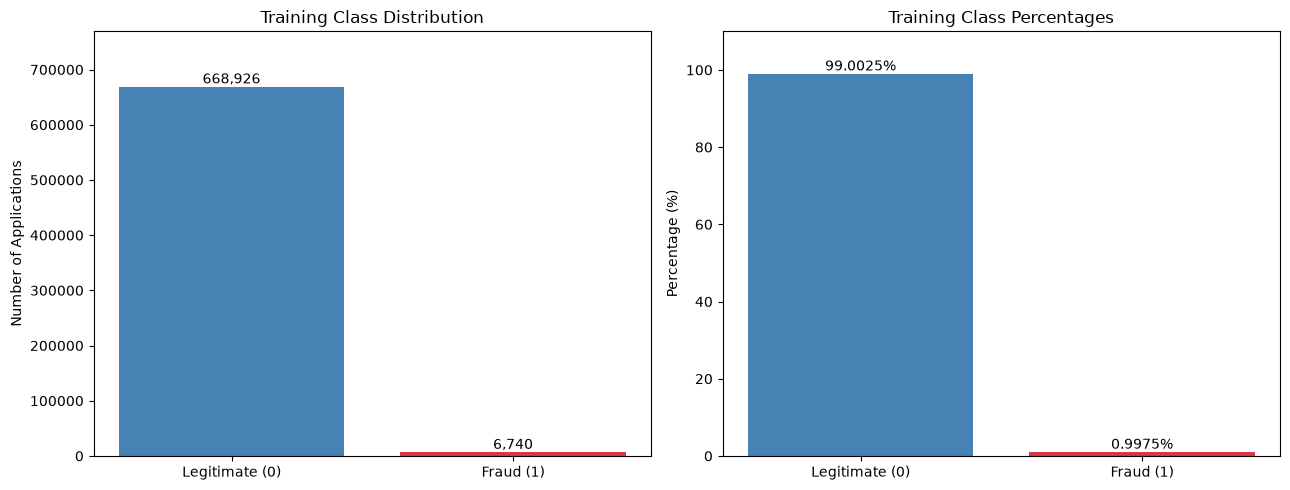

In [33]:

# =====================================================
# 5.3 Class Distribution Visualization
# =====================================================

import matplotlib.pyplot as plt

labels = ["Legitimate (0)", "Fraud (1)"]

counts = [legitimate_count, fraud_count]

percentages = [
    legitimate_percentage,
    fraud_percentage
]

colors = ["#4682B4", "#DC3545"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot absolute class counts
bars = axes[0].bar(labels, counts, color=colors)

axes[0].set_title("Training Class Distribution")
axes[0].set_ylabel("Number of Applications")
axes[0].set_ylim(0, max(counts) * 1.15)

for bar, count in zip(bars, counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

# Plot relative class frequencies
bars = axes[1].bar(labels, percentages, color=colors)

axes[1].set_title("Training Class Percentages")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_ylim(0, 110)

for bar, percentage in zip(bars, percentages):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.4f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



### 5.4 Training Target Distribution — Findings

The training set contains 675,666 applications:

- Legitimate applications: 668,926 (99.0025%).
- Fraudulent applications: 6,740 (0.9975%).

The class imbalance ratio is approximately 99.25:1,
indicating a severely imbalanced classification problem.

### Expected vs. Observed Results

Before the analysis, we expected fraudulent
applications to represent approximately 1%
of the training data.

The observed fraud prevalence of 0.9975%
is consistent with this expectation.

### Implications for Model Evaluation

A classifier that always predicts the majority
class could achieve approximately 99% accuracy
without detecting any fraudulent applications.

Therefore, accuracy alone is insufficient
for evaluating fraud detection models.

Additional evaluation metrics will be required,
including precision, recall, and Average Precision.



## 6. Majority Class Baseline

### Objective

Evaluate a naive classifier that predicts every
application as legitimate, regardless of its features.

This baseline demonstrates the limitations of
accuracy under severe class imbalance.

### Hypothesis Before the Experiment

We expect the majority class classifier to achieve:

- Accuracy of approximately 99%.
- Fraud recall of 0%.
- Fraud precision of 0%, using a zero-division convention.
- F1-score of 0%.

Despite its high expected accuracy, the classifier
will have no practical ability to detect fraud.

The experiment will demonstrate why high accuracy
does not necessarily indicate good fraud detection
performance.


In [34]:

# =====================================================
# 6.1 Majority Class Baseline Experiment
# =====================================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Extract the training target
y_train = train_df["fraud_bool"]

# Create placeholder features
X_dummy_train = np.zeros((len(y_train), 1))

# Initialize the majority class classifier
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Fit the baseline model
dummy_model.fit(X_dummy_train, y_train)

# Generate class predictions
y_dummy_pred = dummy_model.predict(X_dummy_train)

# Generate fraud probability scores
y_dummy_scores = dummy_model.predict_proba(
    X_dummy_train
)[:, 1]

# Calculate evaluation metrics
dummy_accuracy = accuracy_score(y_train, y_dummy_pred)

dummy_precision = precision_score(
    y_train, y_dummy_pred, zero_division=0
)

dummy_recall = recall_score(
    y_train, y_dummy_pred, zero_division=0
)

dummy_f1 = f1_score(
    y_train, y_dummy_pred, zero_division=0
)

dummy_ap = average_precision_score(
    y_train, y_dummy_scores
)

# Display evaluation results
print("=== MAJORITY CLASS BASELINE ===")

print(f"Accuracy:          {dummy_accuracy:.6f}")
print(f"Precision:         {dummy_precision:.6f}")
print(f"Recall:            {dummy_recall:.6f}")
print(f"F1-score:          {dummy_f1:.6f}")
print(f"Average Precision: {dummy_ap:.6f}")

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_train, y_dummy_pred, labels=[0, 1]))


=== MAJORITY CLASS BASELINE ===
Accuracy:          0.990025
Precision:         0.000000
Recall:            0.000000
F1-score:          0.000000
Average Precision: 0.009975

=== CONFUSION MATRIX ===
[[668926      0]
 [  6740      0]]


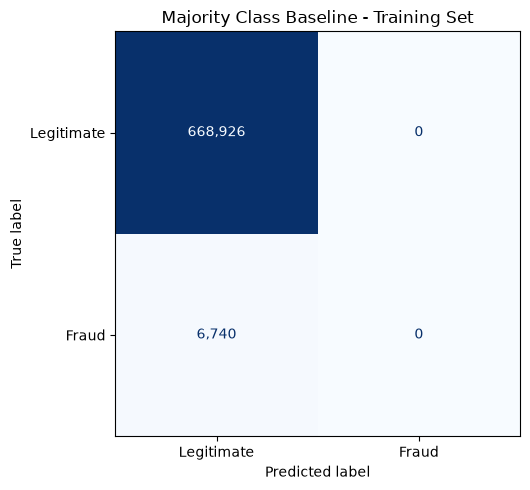

In [35]:


# =====================================================
# 6.2 Majority Class Baseline - Confusion Matrix
# =====================================================

from sklearn.metrics import ConfusionMatrixDisplay

# Calculate the confusion matrix
dummy_cm = confusion_matrix(
    y_train,
    y_dummy_pred,
    labels=[0, 1]
)

# Create the visualization
fig, ax = plt.subplots(figsize=(7, 5))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=dummy_cm,
    display_labels=["Legitimate", "Fraud"]
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format=",d",
    colorbar=False
)

ax.set_title("Majority Class Baseline - Training Set")

plt.tight_layout()
plt.show()



### 6.3 Majority Class Baseline — Findings

The majority class classifier was evaluated
on the training period (months 0–4).

#### Experimental Results

| Metric | Result |
|---|---:|
| Accuracy | 0.990025 |
| Precision | 0.000000 |
| Recall | 0.000000 |
| F1-score | 0.000000 |
| Average Precision | 0.009975 |

#### Confusion Matrix Interpretation

- True Negatives: 668,926
- False Positives: 0
- False Negatives: 6,740
- True Positives: 0

The classifier correctly identifies all legitimate
applications but fails to detect any fraudulent
applications.

Precision is undefined because no positive
predictions are made. It is reported as zero
using the zero-division convention.

#### Expected vs. Observed Results

The experimental results support our initial
hypothesis.

Despite achieving approximately 99% accuracy,
the classifier has zero fraud recall and
provides no useful fraud detection capability.

#### Average Precision Interpretation

The classifier assigns identical fraud scores
to all applications.

Therefore, its Average Precision equals the
fraud prevalence of the evaluated dataset.

This provides a no-discrimination reference
for evaluating future models.

#### Limitations

This experiment was conducted on the training
data for demonstration purposes.

A fair comparison between predictive models
will require evaluation on the same validation
period using consistent evaluation metrics.

#### Conclusion

Accuracy alone is not an appropriate evaluation
criterion for severely imbalanced fraud detection.

Precision, recall, Average Precision, and
Precision-Recall curves should be considered
when evaluating future models.



## 7. Validation Month Analysis

### Objective

Analyze the target distribution in the
validation period (month 5) and compare
it with the training period (months 0–4).

### Research Questions

- What is the fraud prevalence in month 5?
- Does the class distribution differ from
  the training period?
- How might changes in fraud prevalence
  affect model evaluation?

### Expected Findings

We expect the validation dataset to remain
highly imbalanced.

However, the exact fraud prevalence may differ
from the training period due to temporal
changes in the application population.


In [36]:

# =====================================================
# 7.1 Validation Target Distribution
# =====================================================

# Extract validation target
y_val = val_df["fraud_bool"]

# Verify binary target values
assert y_val.isin([0, 1]).all()

# Count observations in each class
val_class_counts = y_val.value_counts()

val_legitimate_count = val_class_counts.get(0, 0)
val_fraud_count = val_class_counts.get(1, 0)

val_total_count = len(y_val)

# Calculate percentages
val_legitimate_percentage = (
    val_legitimate_count / val_total_count * 100
)

val_fraud_percentage = (
    val_fraud_count / val_total_count * 100
)

# Calculate imbalance ratio
val_imbalance_ratio = (
    val_legitimate_count / val_fraud_count
    if val_fraud_count > 0 else np.inf
)

# Calculate change in fraud prevalence
prevalence_difference = (
    val_fraud_percentage - fraud_percentage
)

# Display results
print("=== VALIDATION TARGET DISTRIBUTION ===")

print(f"Total applications: {val_total_count:,}")

print("\nLegitimate applications (Class 0):")
print(f"Count: {val_legitimate_count:,}")
print(f"Percentage: {val_legitimate_percentage:.4f}%")

print("\nFraudulent applications (Class 1):")
print(f"Count: {val_fraud_count:,}")
print(f"Percentage: {val_fraud_percentage:.4f}%")

print("\n=== CLASS IMBALANCE ===")
print(f"Imbalance ratio: {val_imbalance_ratio:.2f}:1")

print("\n=== TRAINING VS. VALIDATION ===")
print(f"Training fraud rate: {fraud_percentage:.4f}%")
print(f"Validation fraud rate: {val_fraud_percentage:.4f}%")
print(f"Difference: {prevalence_difference:+.4f} percentage points")


=== VALIDATION TARGET DISTRIBUTION ===
Total applications: 119,323

Legitimate applications (Class 0):
Count: 117,912
Percentage: 98.8175%

Fraudulent applications (Class 1):
Count: 1,411
Percentage: 1.1825%

=== CLASS IMBALANCE ===
Imbalance ratio: 83.57:1

=== TRAINING VS. VALIDATION ===
Training fraud rate: 0.9975%
Validation fraud rate: 1.1825%
Difference: +0.1850 percentage points


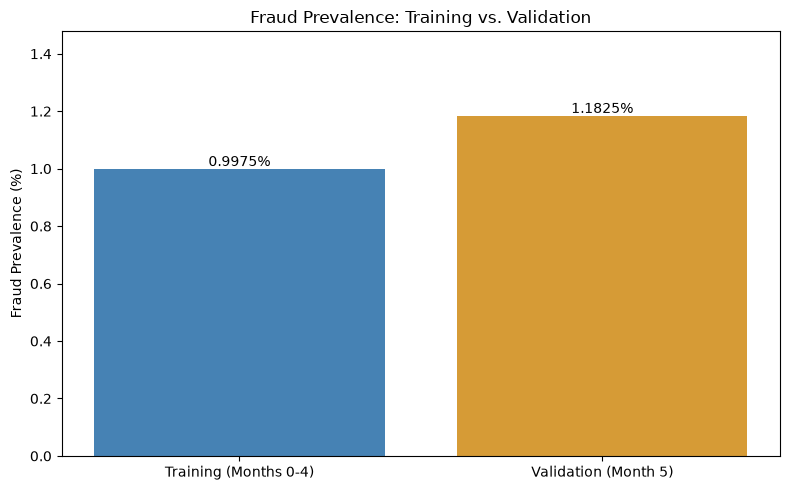

=== FRAUD PREVALENCE CHANGE ===
Absolute change: +0.1850 percentage points
Relative change: +18.54%


In [37]:

# =====================================================
# 7.2 Training vs. Validation Fraud Prevalence
# =====================================================

periods = ["Training (Months 0-4)", "Validation (Month 5)"]

fraud_rates = [
    fraud_percentage,
    val_fraud_percentage
]

colors = ["#4682B4", "#D69B36"]

# Calculate relative change in fraud prevalence
relative_change = (
    (val_fraud_percentage - fraud_percentage)
    / fraud_percentage * 100
)

# Create the comparison plot
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(periods, fraud_rates, color=colors)

ax.set_title("Fraud Prevalence: Training vs. Validation")
ax.set_ylabel("Fraud Prevalence (%)")
ax.set_ylim(0, max(fraud_rates) * 1.25)

# Add percentage labels
for bar, rate in zip(bars, fraud_rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.4f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("=== FRAUD PREVALENCE CHANGE ===")

print(f"Absolute change: {prevalence_difference:+.4f} percentage points")
print(f"Relative change: {relative_change:+.2f}%")



### 7.3 Validation Distribution — Findings

The validation period contains 119,323 applications,
including 1,411 fraudulent applications.

The fraud prevalence increased from 0.9975%
in the training period to 1.1825% in the
validation period.

The absolute increase is approximately
0.1850 percentage points, corresponding
to a relative increase of approximately 18.55%.

### Expected vs. Observed Results

As expected, the validation dataset remains
severely imbalanced.

However, the observed fraud prevalence is
higher than in the training period.

### Implications for Model Evaluation

- Class prevalence is not identical across
  the training and validation periods.
- The majority class accuracy baseline
  depends on the evaluated period.
- The no-discrimination Average Precision
  baseline also depends on fraud prevalence.
- Chronological evaluation is important
  for understanding model generalization.

### Limitations

The observed difference indicates a temporal
change in class prevalence.

However, this observation alone is insufficient
to establish concept drift or determine
the causes of the change.



### 7.4 Majority Class Baseline — Validation

#### Objective

Evaluate the previously fitted majority class
classifier on the validation period (month 5).

The classifier will not be refitted using
validation data.

#### Hypothesis Before the Experiment

Based on the observed validation distribution,
we expect:

- Accuracy of approximately 98.8175%.
- Precision of 0 under the zero-division convention.
- Recall of 0.
- F1-score of 0.
- Average Precision of approximately 0.011825.

The classifier is expected to maintain high
accuracy while failing to detect fraudulent
applications.

This experiment will establish a validation
baseline for subsequent model comparisons.


In [38]:

# =====================================================
# 7.5 Majority Class Baseline - Validation Evaluation
# =====================================================

# Create placeholder validation features
X_dummy_val = np.zeros((len(y_val), 1))

# Generate predictions using the existing fitted model
y_dummy_val_pred = dummy_model.predict(X_dummy_val)

# Generate fraud probability scores
y_dummy_val_scores = dummy_model.predict_proba(
    X_dummy_val
)[:, 1]

# Calculate validation metrics
dummy_val_accuracy = accuracy_score(
    y_val, y_dummy_val_pred
)

dummy_val_precision = precision_score(
    y_val, y_dummy_val_pred, zero_division=0
)

dummy_val_recall = recall_score(
    y_val, y_dummy_val_pred, zero_division=0
)

dummy_val_f1 = f1_score(
    y_val, y_dummy_val_pred, zero_division=0
)

dummy_val_ap = average_precision_score(
    y_val, y_dummy_val_scores
)

# Display validation results
print("=== MAJORITY CLASS BASELINE - VALIDATION ===")

print(f"Accuracy:          {dummy_val_accuracy:.6f}")
print(f"Precision:         {dummy_val_precision:.6f}")
print(f"Recall:            {dummy_val_recall:.6f}")
print(f"F1-score:          {dummy_val_f1:.6f}")
print(f"Average Precision: {dummy_val_ap:.6f}")

# Calculate and display confusion matrix
dummy_val_cm = confusion_matrix(
    y_val,
    y_dummy_val_pred,
    labels=[0, 1]
)

print("\n=== CONFUSION MATRIX ===")
print(dummy_val_cm)


=== MAJORITY CLASS BASELINE - VALIDATION ===
Accuracy:          0.988175
Precision:         0.000000
Recall:            0.000000
F1-score:          0.000000
Average Precision: 0.011825

=== CONFUSION MATRIX ===
[[117912      0]
 [  1411      0]]


=== BASELINE PERFORMANCE COMPARISON ===
           Metric  Training  Validation  Difference
         Accuracy  0.990025    0.988175   -0.001850
        Precision  0.000000    0.000000    0.000000
           Recall  0.000000    0.000000    0.000000
         F1-score  0.000000    0.000000    0.000000
Average Precision  0.009975    0.011825    0.001850


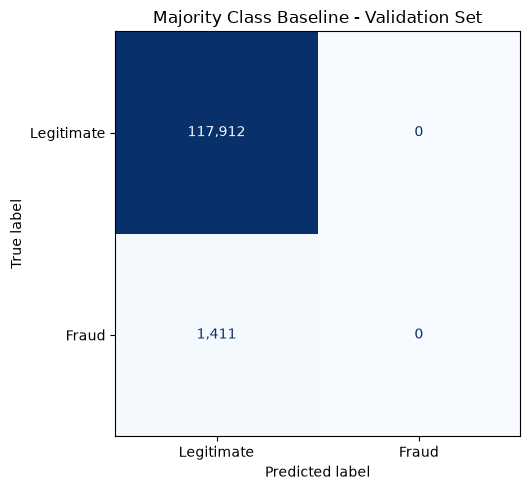

In [39]:

# =====================================================
# 7.6 Training vs. Validation Baseline Comparison
# =====================================================

# Create a comparison table
baseline_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Average Precision"
    ],
    "Training": [
        dummy_accuracy,
        dummy_precision,
        dummy_recall,
        dummy_f1,
        dummy_ap
    ],
    "Validation": [
        dummy_val_accuracy,
        dummy_val_precision,
        dummy_val_recall,
        dummy_val_f1,
        dummy_val_ap
    ]
})

# Calculate the difference between periods
baseline_comparison["Difference"] = (
    baseline_comparison["Validation"]
    - baseline_comparison["Training"]
)

# Display the comparison table
print("=== BASELINE PERFORMANCE COMPARISON ===")

print(
    baseline_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# Visualize the validation confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=dummy_val_cm,
    display_labels=["Legitimate", "Fraud"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format=",d",
    colorbar=False
)

ax.set_title(
    "Majority Class Baseline - Validation Set"
)

plt.tight_layout()
plt.show()



### 7.7 Validation Baseline — Findings and Interpretation

The majority class classifier was evaluated
on month 5 without being refitted on validation data.

### Expected vs. Observed Results

The observed results support our initial hypothesis.

The classifier achieved an accuracy of 98.8175%,
while precision, recall, and F1-score were zero.

Precision is reported as zero using the
zero-division convention because the classifier
produced no positive predictions.

All 1,411 fraudulent applications in the
validation period were incorrectly classified
as legitimate.

### Training vs. Validation Comparison

Although the classifier's prediction strategy
remained unchanged, its accuracy decreased
and its Average Precision increased.

These differences are explained by the higher
fraud prevalence in the validation period,
rather than a change in predictive ability.

The validation Average Precision of 0.011825
represents the no-discrimination reference
for subsequent model evaluations.

### Research Question

What does performing well mean when approximately
99% of applications are legitimate?

The majority class baseline demonstrates that
high accuracy alone does not indicate effective
fraud detection.

A useful fraud detection model should:

- Identify fraudulent applications.
- Maintain an acceptable false positive rate.
- Rank fraudulent applications above legitimate ones.
- Improve upon the no-discrimination baseline.
- Generalize to future observations.

### Limitations

The majority class classifier does not use
application features and cannot distinguish
between fraudulent and legitimate applications.

The observed temporal change in fraud prevalence
does not, by itself, establish concept drift.

### Conclusion

Future models should be evaluated on the same
validation period using consistent metrics,
including Average Precision, precision, recall,
and Precision-Recall curves.

Threshold-dependent performance should also
be examined under relevant false positive
rate constraints.



## 8. Categorical Features and Value Meanings

### Objective

Investigate the categorical features in the
training dataset and understand their meaning,
distribution, and potential preprocessing
requirements.

### Categorical Features

- `payment_type`: Payment type.
- `employment_status`: Employment status.
- `housing_status`: Housing status.
- `source`: Application source.
- `device_os`: Device operating system.

### Research Questions

- How many unique categories does each feature contain?
- What are the possible categorical values?
- Are some categories significantly more frequent
  than others?
- Are there missing or rare categories?
- Does fraud prevalence differ across categories?
- Which encoding methods may be appropriate?

### Expected Findings

We expect the categorical features to contain
a limited number of distinct values.

Some categories may be substantially more
frequent than others.

Fraud prevalence may vary across categories,
but these relationships must be examined
before drawing conclusions.

### Analysis Protocol

The exploratory analysis will be performed
using training data from months 0–4 only.

No categorical encoding or feature removal
will be performed at this stage.


In [40]:

# =====================================================
# 8.1 Categorical Features Overview
# =====================================================

from IPython.display import display
# Identify categorical features in the training data
categorical_features = train_df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Create a list for summary information
categorical_summary = []

# Examine each categorical feature
for feature in categorical_features:

    unique_values = sorted(
        train_df[feature].dropna().unique().tolist()
    )

    categorical_summary.append({
        "Feature": feature,
        "Data Type": str(train_df[feature].dtype),
        "Unique Categories": train_df[feature].nunique(),
        "Missing Values": train_df[feature].isna().sum(),
        "Possible Values": ", ".join(map(str, unique_values))
    })

# Convert the summary into a DataFrame
categorical_summary_df = pd.DataFrame(
    categorical_summary
)

# Display the results
print("=== CATEGORICAL FEATURES OVERVIEW ===")

display(categorical_summary_df)


=== CATEGORICAL FEATURES OVERVIEW ===


,Feature,Data Type,Unique Categories,Missing Values,Possible Values
0,payment_type,str,5,0,"AA, AB, AC, AD, AE"
1,employment_status,str,7,0,"CA, CB, CC, CD, CE, CF, CG"
2,housing_status,str,7,0,"BA, BB, BC, BD, BE, BF, BG"
3,source,str,2,0,"INTERNET, TELEAPP"
4,device_os,str,5,0,"linux, macintosh, other, windows, x11"



### 8.2 Categorical Value Meanings

According to the official BAF dataset datasheet,
the categorical features represent the following:

| Feature | Description | Categories |
|---|---|---|
| payment_type | Credit payment plan type | AA–AE |
| employment_status | Applicant's employment status | CA–CG |
| housing_status | Applicant's residential status | BA–BG |
| source | Application submission channel | INTERNET, TELEAPP |
| device_os | Device operating system | 5 categories |

### Initial Findings

- All five categorical features have low cardinality.
- No explicit missing values (NaN) were detected.
- There are 26 categories across the five features.
- Some categorical values are anonymized.

### Anonymization Limitations

The original meanings of individual codes in
payment_type, employment_status, and housing_status
are not disclosed in the official documentation.

Therefore, these codes should be treated as
nominal categories without assuming a natural
ordering or assigning unsupported meanings.

The absence of NaN values does not necessarily
exclude implicit unknown categories.

### Preliminary Preprocessing Considerations

One-Hot Encoding is a potential preprocessing
method because the categorical features have
relatively low cardinality.

No encoding has been applied at this stage.

### Reference

[Official BAF Dataset Datasheet — Q7](https://raw.githubusercontent.com/feedzai/bank-account-fraud/main/documents/datasheet.pdf)


In [41]:

# =====================================================
# 8.3 Category Frequency Distribution
# =====================================================

# Store category distributions for further analysis
category_distributions = {}

# Analyze each categorical feature
for feature in categorical_features:

    # Calculate category counts
    counts = train_df[feature].value_counts(
        dropna=False
    )

    # Calculate category percentages
    percentages = (
        counts / len(train_df) * 100
    )

    # Create a summary table
    distribution = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages
    })

    # Store the distribution
    category_distributions[feature] = distribution

    # Display the results
    print(f"\n=== {feature.upper()} ===")

    display(distribution.round(4))



=== PAYMENT_TYPE ===


,Count,Percentage (%)
payment_type,,
AB,235411,34.8413
AA,181299,26.8326
AC,171511,25.3840
AD,87209,12.9071
AE,236,0.0349



=== EMPLOYMENT_STATUS ===


,Count,Percentage (%)
employment_status,,
CA,480770,71.1550
CB,102251,15.1334
CF,30444,4.5058
CC,27614,4.0869
CD,19680,2.9127
CE,14581,2.1580
CG,326,0.0482



=== HOUSING_STATUS ===


,Count,Percentage (%)
housing_status,,
BC,262914,38.9118
BB,171639,25.4029
BE,115214,17.0519
BA,110423,16.3428
BD,14074,2.0830
BF,1201,0.1778
BG,201,0.0297



=== SOURCE ===


,Count,Percentage (%)
source,,
INTERNET,670596,99.2496
TELEAPP,5070,0.7504



=== DEVICE_OS ===


,Count,Percentage (%)
device_os,,
linux,232252,34.3738
other,220215,32.5923
windows,182429,26.9999
macintosh,35809,5.2998
x11,4961,0.7342


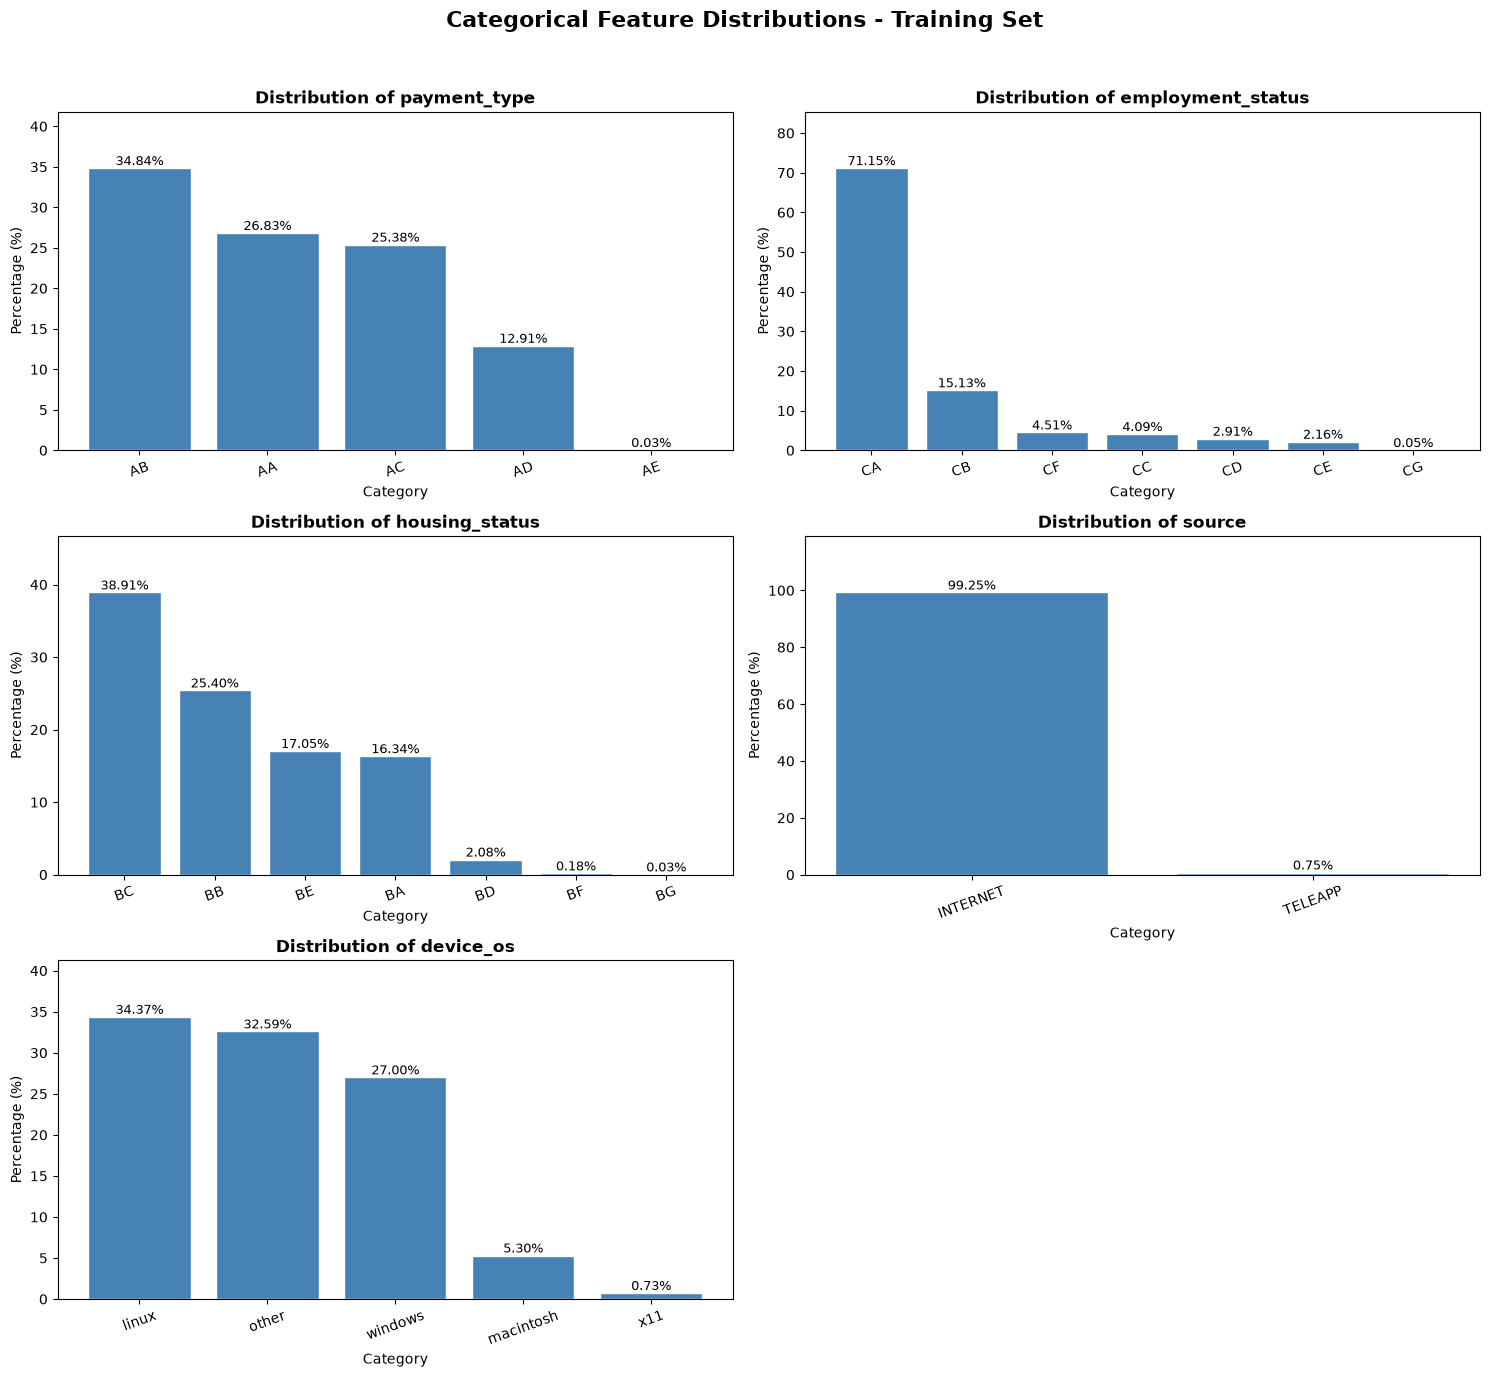

In [42]:

# =====================================================
# 8.4 Categorical Distribution Visualization
# =====================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    distribution = category_distributions[feature]

    # Extract category names and percentages
    categories = distribution.index.astype(str)

    percentages = distribution["Percentage (%)"]

    # Create the bar chart
    bars = axes[i].bar(
        categories,
        percentages,
        color="#4682B4",
        edgecolor="white"
    )

    # Configure the chart
    axes[i].set_title(
        f"Distribution of {feature}",
        fontweight="bold"
    )

    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Percentage (%)")

    axes[i].set_ylim(
        0, percentages.max() * 1.20
    )

    # Add percentage labels
    for bar, percentage in zip(bars, percentages):

        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{percentage:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

    axes[i].tick_params(
        axis="x", rotation=20
    )

# Remove unused subplot
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Categorical Feature Distributions - Training Set",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()



### 8.5 Category Distribution — Findings

The categorical feature distributions reveal
substantial differences in category frequencies.

#### Key Observations

- AB is the most frequent payment type (34.84%).
- CA dominates employment status (71.15%).
- BC is the most frequent housing status (38.91%).
- INTERNET accounts for 99.25% of applications.
- Several categories represent less than 1%
  of the training observations.

#### Implications

Some categorical features contain highly
uneven category distributions.

Rare categories may contain relatively few
observations, making their estimated fraud
rates less reliable.

However, low frequency does not necessarily
indicate low predictive value.

Therefore, rare categories should not be
removed solely because of their frequency.

Further analysis is required to understand
the relationship between categorical values
and fraud prevalence.


In [43]:

# =====================================================
# 8.6 Rare Categories Analysis
# =====================================================

# Define the exploratory rarity threshold
rare_threshold = 1.0

rare_categories = []

# Identify categories below the threshold
for feature in categorical_features:

    distribution = category_distributions[feature]

    rare = distribution[
        distribution["Percentage (%)"] < rare_threshold
    ]

    for category, row in rare.iterrows():

        rare_categories.append({
            "Feature": feature,
            "Category": category,
            "Count": int(row["Count"]),
            "Percentage (%)": row["Percentage (%)"]
        })

# Create a summary table
rare_categories_df = pd.DataFrame(rare_categories)

# Sort categories by frequency
rare_categories_df = rare_categories_df.sort_values(
    by="Percentage (%)"
).reset_index(drop=True)

# Display results
print("=== RARE CATEGORIES ANALYSIS ===")
print(f"Rarity threshold: {rare_threshold}%")
print(f"Number of rare categories: {len(rare_categories_df)}")

display(rare_categories_df.round(4))


=== RARE CATEGORIES ANALYSIS ===
Rarity threshold: 1.0%
Number of rare categories: 6


,Feature,Category,Count,Percentage (%)
0,housing_status,BG,201,0.0297
1,payment_type,AE,236,0.0349
2,employment_status,CG,326,0.0482
3,housing_status,BF,1201,0.1778
4,device_os,x11,4961,0.7342
5,source,TELEAPP,5070,0.7504



### 8.7 Fraud Prevalence by Category

#### Objective

Examine the relationship between categorical
feature values and fraud prevalence within
the training dataset.

#### Research Questions

- Does fraud prevalence vary across categories?
- Which categories have higher fraud rates
  than the overall training fraud rate?
- Do rare categories exhibit extreme fraud rates?
- Are the observed rates supported by sufficient
  numbers of observations?

#### Expected Findings

We expect fraud prevalence to vary across
categorical values.

However, estimates for rare categories may
be less reliable because of their limited
sample sizes.

Observed associations should not be interpreted
as causal relationships.


In [44]:

# =====================================================
# 8.8 Fraud Prevalence by Category
# =====================================================

category_fraud_statistics = {}

# Overall training fraud prevalence
overall_fraud_rate = train_df["fraud_bool"].mean() * 100

print(f"Overall training fraud rate: {overall_fraud_rate:.4f}%")

for feature in categorical_features:

    # Calculate statistics for each category
    statistics = train_df.groupby(
        feature,
        dropna=False
    ).agg(
        Total_Applications=("fraud_bool", "size"),
        Fraud_Count=("fraud_bool", "sum")
    )

    # Calculate legitimate applications
    statistics["Legitimate_Count"] = (
        statistics["Total_Applications"]
        - statistics["Fraud_Count"]
    )

    # Calculate category frequency
    statistics["Category_Percentage"] = (
        statistics["Total_Applications"]
        / len(train_df) * 100
    )

    # Calculate fraud prevalence
    statistics["Fraud_Rate (%)"] = (
        statistics["Fraud_Count"]
        / statistics["Total_Applications"] * 100
    )

    # Calculate relative fraud rate
    statistics["Fraud_Lift"] = (
        statistics["Fraud_Rate (%)"]
        / overall_fraud_rate
    )

    # Identify rare categories
    statistics["Rare_Category"] = (
        statistics["Category_Percentage"] < rare_threshold
    )

    # Sort by fraud rate
    statistics = statistics.sort_values(
        by="Fraud_Rate (%)",
        ascending=False
    )

    # Store results
    category_fraud_statistics[feature] = statistics

    # Display results
    print(f"\n=== {feature.upper()} ===")

    display(statistics.round(4))


Overall training fraud rate: 0.9975%

=== PAYMENT_TYPE ===


,Total_Applications,Fraud_Count,Legitimate_Count,Category_Percentage,Fraud_Rate (%),Fraud_Lift,Rare_Category
payment_type,,,,,,,
AC,171511,2607,168904,25.3840,1.5200,1.5238,False
AB,235411,2390,233021,34.8413,1.0152,1.0178,False
AD,87209,815,86394,12.9071,0.9345,0.9368,False
AA,181299,927,180372,26.8326,0.5113,0.5126,False
AE,236,1,235,0.0349,0.4237,0.4248,True



=== EMPLOYMENT_STATUS ===


,Total_Applications,Fraud_Count,Legitimate_Count,Category_Percentage,Fraud_Rate (%),Fraud_Lift,Rare_Category
employment_status,,,,,,,
CC,27614,637,26977,4.0869,2.3068,2.3125,False
CG,326,4,322,0.0482,1.2270,1.2300,True
CA,480770,5309,475461,71.1550,1.1043,1.1070,False
CB,102251,626,101625,15.1334,0.6122,0.6137,False
CD,19680,76,19604,2.9127,0.3862,0.3871,False
CE,14581,33,14548,2.1580,0.2263,0.2269,False
CF,30444,55,30389,4.5058,0.1807,0.1811,False



=== HOUSING_STATUS ===


,Total_Applications,Fraud_Count,Legitimate_Count,Category_Percentage,Fraud_Rate (%),Fraud_Lift,Rare_Category
housing_status,,,,,,,
BA,110423,3778,106645,16.3428,3.4214,3.4298,False
BD,14074,121,13953,2.0830,0.8597,0.8619,False
BC,262914,1496,261418,38.9118,0.5690,0.5704,False
BB,171639,967,170672,25.4029,0.5634,0.5648,False
BF,1201,6,1195,0.1778,0.4996,0.5008,True
BG,201,1,200,0.0297,0.4975,0.4987,True
BE,115214,371,114843,17.0519,0.3220,0.3228,False



=== SOURCE ===


,Total_Applications,Fraud_Count,Legitimate_Count,Category_Percentage,Fraud_Rate (%),Fraud_Lift,Rare_Category
source,,,,,,,
TELEAPP,5070,73,4997,0.7504,1.4398,1.4434,True
INTERNET,670596,6667,663929,99.2496,0.9942,0.9966,False



=== DEVICE_OS ===


,Total_Applications,Fraud_Count,Legitimate_Count,Category_Percentage,Fraud_Rate (%),Fraud_Lift,Rare_Category
device_os,,,,,,,
windows,182429,4096,178333,26.9999,2.2453,2.2508,False
macintosh,35809,431,35378,5.2998,1.2036,1.2066,False
x11,4961,53,4908,0.7342,1.0683,1.0710,True
other,220215,1150,219065,32.5923,0.5222,0.5235,False
linux,232252,1010,231242,34.3738,0.4349,0.4359,False


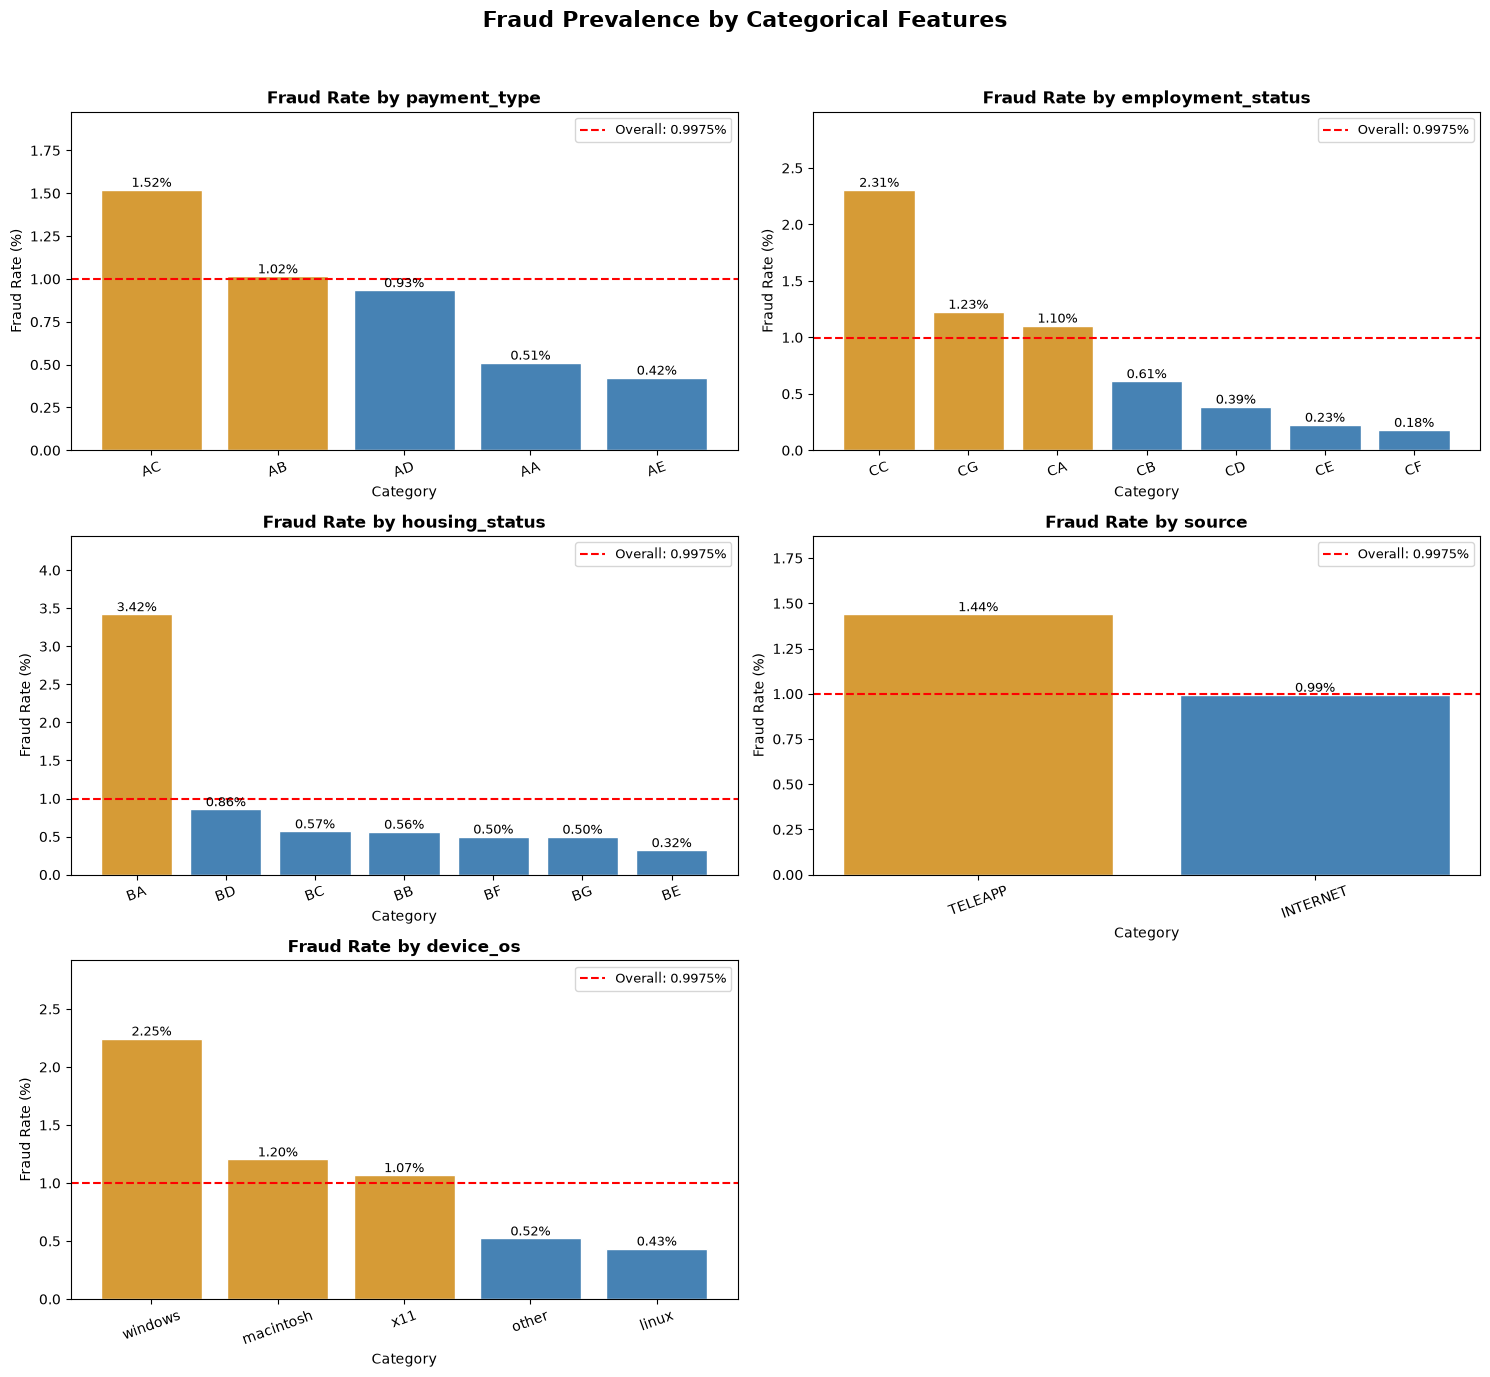

In [45]:

# =====================================================
# 8.9 Fraud Prevalence by Category - Visualization
# =====================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    statistics = category_fraud_statistics[feature]

    categories = statistics.index.astype(str)
    fraud_rates = statistics["Fraud_Rate (%)"]

    # Assign colors according to the overall fraud rate
    colors = [
        "#D69B36" if rate > overall_fraud_rate
        else "#4682B4"
        for rate in fraud_rates
    ]

    # Create the bar chart
    bars = axes[i].bar(
        categories,
        fraud_rates,
        color=colors,
        edgecolor="white"
    )

    # Add the overall fraud prevalence reference line
    axes[i].axhline(
        y=overall_fraud_rate,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Overall: {overall_fraud_rate:.4f}%"
    )

    # Configure the chart
    axes[i].set_title(
        f"Fraud Rate by {feature}",
        fontweight="bold"
    )

    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Fraud Rate (%)")

    axes[i].set_ylim(
        0,
        max(fraud_rates.max(), overall_fraud_rate) * 1.30
    )

    # Add percentage labels
    for bar, rate in zip(bars, fraud_rates):

        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{rate:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

    axes[i].tick_params(axis="x", rotation=20)

    axes[i].legend(fontsize=9)

# Remove unused subplot
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Fraud Prevalence by Categorical Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [46]:

# =====================================================
# 8.10 Rare Categories and Fraud Risk
# =====================================================

rare_fraud_results = []

for feature in categorical_features:

    statistics = category_fraud_statistics[feature]

    # Select rare categories
    rare_statistics = statistics[
        statistics["Rare_Category"]
    ]

    for category, row in rare_statistics.iterrows():

        rare_fraud_results.append({
            "Feature": feature,
            "Category": category,
            "Applications": int(row["Total_Applications"]),
            "Fraud Count": int(row["Fraud_Count"]),
            "Frequency (%)": row["Category_Percentage"],
            "Fraud Rate (%)": row["Fraud_Rate (%)"],
            "Fraud Lift": row["Fraud_Lift"]
        })

# Create a consolidated summary
rare_fraud_df = pd.DataFrame(rare_fraud_results)

# Sort by fraud rate
rare_fraud_df = rare_fraud_df.sort_values(
    by="Fraud Rate (%)",
    ascending=False
).reset_index(drop=True)

print("=== RARE CATEGORIES AND FRAUD RISK ===")

print(f"Overall fraud rate: {overall_fraud_rate:.4f}%")

display(rare_fraud_df.round(4))


=== RARE CATEGORIES AND FRAUD RISK ===
Overall fraud rate: 0.9975%


,Feature,Category,Applications,Fraud Count,Frequency (%),Fraud Rate (%),Fraud Lift
0,source,TELEAPP,5070,73,0.7504,1.4398,1.4434
1,employment_status,CG,326,4,0.0482,1.2270,1.2300
2,device_os,x11,4961,53,0.7342,1.0683,1.0710
3,housing_status,BF,1201,6,0.1778,0.4996,0.5008
4,housing_status,BG,201,1,0.0297,0.4975,0.4987
5,payment_type,AE,236,1,0.0349,0.4237,0.4248



### 8.11 Categorical Features — Final Findings

#### Summary of Observations

The training dataset contains five categorical
features with a total of 26 distinct categories
across these features.

No explicit missing values (NaN) were detected.

The analysis revealed substantial differences
in both category frequencies and fraud prevalence.

#### Fraud Prevalence Findings

The overall training fraud rate is 0.9975%.

The categories with the highest observed fraud
rate within each categorical feature are:

| Feature | Category | Fraud Rate |
|---|---|---:|
| payment_type | AC | 1.52% |
| employment_status | CC | 2.31% |
| housing_status | BA | 3.42% |
| source | TELEAPP | 1.44% |
| device_os | windows | 2.25% |

The observed differences suggest that categorical
features may contain useful predictive information.

However, these associations do not establish
causality or guarantee predictive performance
on future data.

#### Rare Categories

Using an exploratory frequency threshold of 1%,
six rare categories were identified.

Three categories have fraud rates above the
overall training fraud rate:

- TELEAPP
- CG
- x11

Three categories have fraud rates below the
overall training fraud rate:

- BF
- BG
- AE

Therefore, category rarity alone does not
indicate higher fraud prevalence.

Some rare categories contain very few fraud
observations, making their estimated fraud
rates potentially unstable.

#### Expected vs. Observed Results

The observed results support our initial
expectations:

- Categorical features have low cardinality.
- Category frequencies are uneven.
- Fraud prevalence varies across categories.

The analysis also shows that rare categories
do not consistently exhibit higher fraud rates.

#### Proposed Encoding Strategy

One-Hot Encoding is proposed as an initial
encoding method for the categorical features.

Reasons:

- All five features have low cardinality.
- The categories are treated as nominal values.
- An artificial numerical ordering should
  not be introduced.
- One-Hot Encoding is compatible with
  Logistic Regression.

The encoder should be fitted exclusively
on the training dataset.

The same fitted encoder should be used to
transform validation and future test data.

Unknown categories should be handled using
handle_unknown="ignore".

#### Rare Category Handling

All categories will initially be retained.

Rare categories will not be removed or merged
solely because of their low frequency.

Alternative handling strategies may be evaluated
if supported by subsequent experimental results.

#### Limitations

- The original meanings of anonymized category
  codes are not fully available.
- Fraud rate estimates for rare categories
  may be unstable.
- Observed associations do not imply causation.
- Predictive usefulness must be evaluated
  on chronological validation data.

#### Conclusion

Categorical features may contribute useful
information to fraud detection.

One-Hot Encoding is a reasonable initial
preprocessing strategy.

No encoding, category merging, or feature
removal has been performed at this stage.

All exploratory analyses were conducted
using training months 0–4 only.



## 9. Missing Values and Sentinel Values

### 9.1 Objective

The objective of this section is to investigate
how missing or unavailable information is
represented in the BAF dataset.

The analysis focuses on:

- Explicit missing values (NaN).
- Negative numerical values.
- Potential sentinel values.
- The frequency of sentinel values.
- The relationship between sentinel values
  and fraud prevalence.
- Implications for future preprocessing.

### Research Questions

1. Does the training dataset contain explicit
   missing values?

2. Are missing or unavailable values represented
   using special numerical codes?

3. Which features contain potential sentinel
   values?

4. Is the presence of sentinel values associated
   with differences in fraud prevalence?

5. How should sentinel values be handled during
   model preprocessing?

### Initial Hypotheses

- The dataset may contain few or no explicit
  missing values.

- Some numerical features may use negative
  values to represent unavailable information.

- Missingness may contain useful predictive
  information for fraud detection.

- Not all negative values necessarily represent
  missing information.

### Analysis Protocol

All exploratory analyses in this section will
be performed using training months 0-4 only.

Potential sentinel values will be interpreted
according to the official dataset documentation.

No imputation, replacement, or feature removal
will be performed before understanding the
meaning of these values.


In [47]:

# =====================================================
# 9.2 Explicit Missing Values Analysis
# =====================================================

from IPython.display import display as show_table

# Count explicit missing values in each column
missing_counts = train_df.isna().sum()

# Calculate the percentage of missing values
missing_percentages = (
    missing_counts / len(train_df) * 100
)

# Create a summary DataFrame
missing_summary_df = pd.DataFrame({
    "Feature": missing_counts.index,
    "Missing Count": missing_counts.values,
    "Missing Percentage (%)": missing_percentages.values
})

# Sort features by missing value count
missing_summary_df = missing_summary_df.sort_values(
    by="Missing Count",
    ascending=False
).reset_index(drop=True)

# Calculate overall missing value statistics
total_missing_values = int(missing_counts.sum())

features_with_missing = int(
    (missing_counts > 0).sum()
)

rows_with_missing = int(
    train_df.isna().any(axis=1).sum()
)

# Display overall results
print("=== EXPLICIT MISSING VALUES ANALYSIS ===")

print(f"Training observations: {len(train_df):,}")
print(f"Total columns: {train_df.shape[1]}")

print(f"Total missing values: {total_missing_values:,}")
print(f"Columns with missing values: {features_with_missing}")
print(f"Rows with missing values: {rows_with_missing:,}")

print("\n=== MISSING VALUES BY FEATURE ===")

show_table(missing_summary_df)


=== EXPLICIT MISSING VALUES ANALYSIS ===
Training observations: 675,666
Total columns: 32
Total missing values: 0
Columns with missing values: 0
Rows with missing values: 0

=== MISSING VALUES BY FEATURE ===


,Feature,Missing Count,Missing Percentage (%)
0,fraud_bool,0,0.0
1,income,0,0.0
2,name_email_similarity,0,0.0
3,prev_address_months_count,0,0.0
4,current_address_months_count,0,0.0
5,customer_age,0,0.0
6,days_since_request,0,0.0
7,intended_balcon_amount,0,0.0
8,payment_type,0,0.0
9,zip_count_4w,0,0.0



### 9.3 Explicit Missing Values — Findings

#### Observed Results

The explicit missing values analysis was performed
on the training dataset (months 0–4).

| Metric | Result |
|---|---:|
| Training observations | 675,666 |
| Total columns | 32 |
| Total data entries | 21,621,312 |
| Explicit missing values | 0 |
| Columns with missing values | 0 |
| Rows with missing values | 0 |
| Missing percentage | 0.00% |

#### Interpretation

No explicit missing values were detected in any
of the 32 columns of the training dataset.

This result supports our initial hypothesis
that the dataset may contain few or no
explicit missing values.

However, the absence of NaN values does not
necessarily indicate that all information
is available or complete.

Missing or unavailable information may be
represented using special numerical codes
known as sentinel values.

#### Preprocessing Implications

At this stage:

- No explicit missing values require imputation.
- No rows or columns need to be removed due
  to explicit missing values.
- Potential sentinel values require further
  investigation.
- No modifications have been made to the
  original training data.

#### Next Step

Investigate negative numerical values to
identify potential sentinel values.

Negative values will not automatically be
classified as missing information.


In [52]:

# =====================================================
# 9.4 Negative Numerical Values Analysis
# =====================================================

# Identify numerical features
# Exclude the target variable and temporal split column
numerical_columns = (
    train_df.select_dtypes(include="number")
    .columns
    .drop(["fraud_bool", "month"])
    .tolist()
)

# Initialize a list for storing results
negative_summary = []

# Analyze each numerical feature
for feature in numerical_columns:

    # Select the current feature
    values = train_df[feature]

    # Identify negative values
    negative_values = values[values < 0]

    # Count negative observations
    negative_count = len(negative_values)

    # Calculate negative value percentage
    negative_percentage = (
        negative_count / len(train_df) * 100
    )

    # Identify distinct negative values
    unique_negative_values = sorted(
        negative_values.unique().tolist()
    )

    # Count occurrences of -1
    minus_one_count = int((values == -1).sum())

    # Store results only for features
    # containing negative values
    if negative_count > 0:

        negative_summary.append({
            "Feature": feature,
            "Minimum Value": values.min(),
            "Maximum Value": values.max(),
            "Negative Count": negative_count,
            "Negative Percentage (%)": round(
                negative_percentage, 4
            ),
            "Unique Negative Values": len(
                unique_negative_values
            ),
            "Negative Values Sample":
                unique_negative_values[:10],
            "Minus One Count": minus_one_count
        })

# Create a summary DataFrame
negative_summary_df = pd.DataFrame(
    negative_summary
)

# Display the results
print("=== NEGATIVE NUMERICAL VALUES ANALYSIS ===")

print(f"Numerical features analyzed: {len(numerical_columns)}")

print(
    f"Features containing negative values: "
    f"{len(negative_summary_df)}"
)

if not negative_summary_df.empty:

    negative_summary_df = (
        negative_summary_df.sort_values(
            by="Negative Count",
            ascending=False
        ).reset_index(drop=True)
    )

    print("\n=== NEGATIVE VALUES SUMMARY ===")

    show_table(negative_summary_df)

else:
    print("No negative numerical values were found.")


=== NEGATIVE NUMERICAL VALUES ANALYSIS ===
Numerical features analyzed: 25
Features containing negative values: 8

=== NEGATIVE VALUES SUMMARY ===


,Feature,Minimum Value,Maximum Value,Negative Count,Negative Percentage (%),Unique Negative Values,Negative Values Sample,Minus One Count
0,intended_balcon_amount,-15.167388,112.956928,493751,73.0762,491637,"[-15.167388, -14.06498, -13.202786, -13.105831...",0
1,prev_address_months_count,-1.000000,377.000000,469907,69.5472,1,[-1],469907
2,bank_months_count,-1.000000,32.000000,172287,25.4988,1,[-1],172287
3,credit_risk_score,-170.000000,389.000000,12177,1.8022,164,"[-170, -169, -168, -167, -166, -165, -164, -15...",438
4,current_address_months_count,-1.000000,425.000000,2827,0.4184,1,[-1],2827
5,session_length_in_minutes,-1.000000,85.899143,1278,0.1891,1,[-1.0],1278
6,device_distinct_emails_8w,-1.000000,2.000000,276,0.0408,1,[-1],276
7,velocity_6h,-130.456928,16715.565404,9,0.0013,9,"[-130.456928, -122.071682, -80.69067, -69.8700...",0



### Negative Numerical Values — Findings

The analysis identified negative values in 8 out
of the 25 numerical features examined.

Five features contain -1 as their only negative
value:

- prev_address_months_count
- bank_months_count
- current_address_months_count
- session_length_in_minutes
- device_distinct_emails_8w

Three additional features contain multiple
distinct negative values:

- intended_balcon_amount
- credit_risk_score
- velocity_6h

The presence of negative values does not
automatically indicate missing information.

For example, credit_risk_score contains 164
distinct negative values, including 438
occurrences of -1.

Therefore, a universal rule that replaces all
negative values or all occurrences of -1
would be inappropriate.

Feature-specific missing-value rules are
required and must be based on the official
dataset documentation.


In [49]:

# =====================================================
# 9.5 Confirmed Sentinel Values Identification
# =====================================================

# Missing-value rules based on the official BAF datasheet
sentinel_rules = {
    "prev_address_months_count": "equal_minus_one",
    "current_address_months_count": "equal_minus_one",
    "bank_months_count": "equal_minus_one",
    "session_length_in_minutes": "equal_minus_one",
    "device_distinct_emails_8w": "equal_minus_one",
    "intended_balcon_amount": "negative_values"
}

# Initialize containers
sentinel_summary = []
sentinel_masks = {}

# Analyze confirmed sentinel values
for feature, rule in sentinel_rules.items():

    # Select the feature
    values = train_df[feature]

    # Apply the appropriate missing-value rule
    if rule == "equal_minus_one":

        mask = values == -1
        condition = "== -1"

    elif rule == "negative_values":

        mask = values < 0
        condition = "< 0"

    # Store the Boolean mask
    sentinel_masks[feature] = mask

    # Count confirmed sentinel values
    sentinel_count = int(mask.sum())

    # Calculate the sentinel percentage
    sentinel_percentage = (
        sentinel_count / len(train_df) * 100
    )

    # Count available observations
    available_count = len(train_df) - sentinel_count

    # Store feature-level results
    sentinel_summary.append({
        "Feature": feature,
        "Sentinel Rule": condition,
        "Sentinel Count": sentinel_count,
        "Sentinel Percentage (%)": round(
            sentinel_percentage, 4
        ),
        "Available Count": available_count,
        "Available Percentage (%)": round(
            100 - sentinel_percentage, 4
        )
    })

# Create and sort the summary table
sentinel_summary_df = (
    pd.DataFrame(sentinel_summary)
    .sort_values(
        by="Sentinel Count",
        ascending=False
    )
    .reset_index(drop=True)
)

# Combine Boolean masks into a DataFrame
sentinel_mask_df = pd.DataFrame(sentinel_masks)

# Calculate overall sentinel statistics
total_sentinel_values = int(
    sentinel_mask_df.sum().sum()
)

rows_with_sentinel = int(
    sentinel_mask_df.any(axis=1).sum()
)

rows_without_sentinel = (
    len(train_df) - rows_with_sentinel
)

rows_with_sentinel_percentage = (
    rows_with_sentinel / len(train_df) * 100
)

# Display overall results
print("=== CONFIRMED SENTINEL VALUES ===")

print(f"Training observations: {len(train_df):,}")

print(
    f"Features containing sentinel values: "
    f"{len(sentinel_rules)}"
)

print(
    f"Total sentinel values: "
    f"{total_sentinel_values:,}"
)

print(
    f"Rows with at least one sentinel value: "
    f"{rows_with_sentinel:,}"
)

print(
    f"Percentage of rows with sentinel values: "
    f"{rows_with_sentinel_percentage:.4f}%"
)

print(
    f"Rows without sentinel values: "
    f"{rows_without_sentinel:,}"
)

print("\n=== SENTINEL VALUES BY FEATURE ===")

show_table(sentinel_summary_df)


=== CONFIRMED SENTINEL VALUES ===
Training observations: 675,666
Features containing sentinel values: 6
Total sentinel values: 1,140,326
Rows with at least one sentinel value: 628,074
Percentage of rows with sentinel values: 92.9563%
Rows without sentinel values: 47,592

=== SENTINEL VALUES BY FEATURE ===


,Feature,Sentinel Rule,Sentinel Count,Sentinel Percentage (%),Available Count,Available Percentage (%)
0,intended_balcon_amount,< 0,493751,73.0762,181915,26.9238
1,prev_address_months_count,== -1,469907,69.5472,205759,30.4528
2,bank_months_count,== -1,172287,25.4988,503379,74.5012
3,current_address_months_count,== -1,2827,0.4184,672839,99.5816
4,session_length_in_minutes,== -1,1278,0.1891,674388,99.8109
5,device_distinct_emails_8w,== -1,276,0.0408,675390,99.9592



### Sentinel Values — Findings

#### Observed Results

Six features were identified as containing
encoded missing information according to
the defined sentinel rules.

| Metric | Result |
|---|---:|
| Training observations | 675,666 |
| Features with sentinel values | 6 |
| Total sentinel values | 1,140,326 |
| Applications with sentinel values | 628,074 |
| Applications without sentinel values | 47,592 |
| Percentage with sentinel values | 92.9563% |

#### Feature-Level Observations

The highest sentinel percentages were observed in:

- intended_balcon_amount: 73.0762%
- prev_address_months_count: 69.5472%
- bank_months_count: 25.4988%

The remaining three features contain sentinel
values in less than 1% of training applications.

#### Interpretation

Although no explicit NaN values were detected,
encoded missing information is highly prevalent
in the training dataset.

This demonstrates that checking for NaN values
alone is insufficient for understanding data
completeness.

#### Preprocessing Implications

Removing all applications containing sentinel
values would eliminate approximately 92.96%
of the training dataset.

Therefore, complete-case deletion is not
considered an appropriate default strategy.

Alternative preprocessing strategies should
be investigated before model training.

No original values have been modified.


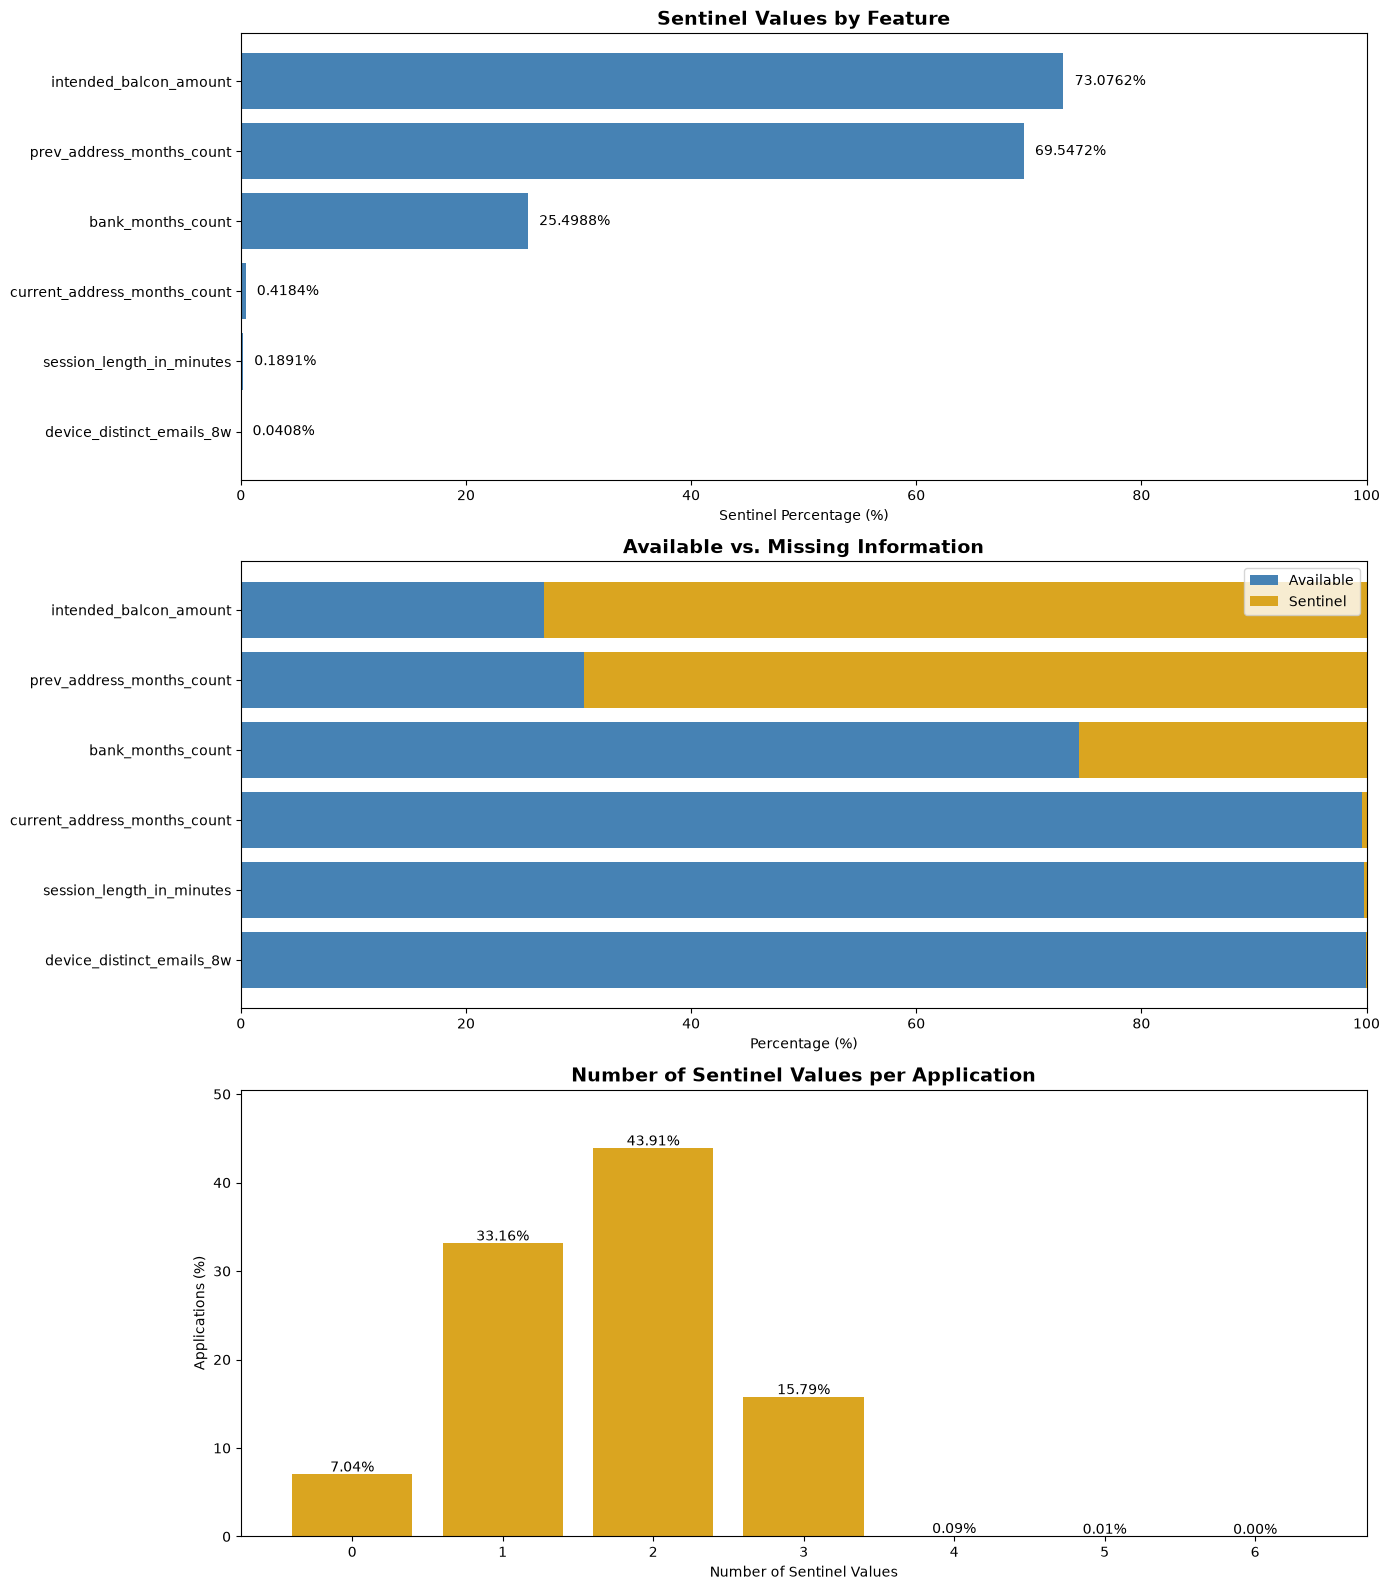

=== SENTINEL VALUES PER APPLICATION ===


,Sentinel Values per Application,Application Count,Application Percentage (%)
0,0,47592,7.0437
1,1,224029,33.1568
2,2,296654,43.9054
3,3,106671,15.7875
4,4,624,0.0924
5,5,96,0.0142
6,6,0,0.0000



Average sentinel values per application: 1.6877
Maximum sentinel values in one application: 5


In [50]:

# =====================================================
# 9.6 Sentinel Values Visualization
# =====================================================

import matplotlib.pyplot as plt

# Prepare feature-level visualization data
plot_df = sentinel_summary_df.sort_values(
    by="Sentinel Percentage (%)",
    ascending=True
)

# Create the figure
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 16)
)

# -----------------------------------------------------
# Plot 1: Sentinel percentage by feature
# -----------------------------------------------------

bars = axes[0].barh(
    plot_df["Feature"],
    plot_df["Sentinel Percentage (%)"],
    color="steelblue"
)

axes[0].set_title(
    "Sentinel Values by Feature",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Sentinel Percentage (%)")
axes[0].set_xlim(0, 100)

# Add percentage labels
for bar, percentage in zip(
    bars,
    plot_df["Sentinel Percentage (%)"]
):
    axes[0].text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.4f}%",
        va="center"
    )

# -----------------------------------------------------
# Plot 2: Available vs. missing information
# -----------------------------------------------------

axes[1].barh(
    plot_df["Feature"],
    plot_df["Available Percentage (%)"],
    color="steelblue",
    label="Available"
)

axes[1].barh(
    plot_df["Feature"],
    plot_df["Sentinel Percentage (%)"],
    left=plot_df["Available Percentage (%)"],
    color="goldenrod",
    label="Sentinel"
)

axes[1].set_title(
    "Available vs. Missing Information",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Percentage (%)")
axes[1].set_xlim(0, 100)
axes[1].legend()

# -----------------------------------------------------
# Plot 3: Number of sentinel values per application
# -----------------------------------------------------

# Count sentinel values in each application
sentinel_count_per_row = sentinel_mask_df.sum(axis=1)

# Calculate the distribution
sentinel_row_distribution = (
    sentinel_count_per_row
    .value_counts()
    .reindex(
        range(len(sentinel_rules) + 1),
        fill_value=0
    )
    .sort_index()
)

# Calculate percentages
sentinel_row_percentages = (
    sentinel_row_distribution / len(train_df) * 100
)

bars = axes[2].bar(
    sentinel_row_distribution.index,
    sentinel_row_percentages.values,
    color="goldenrod"
)

axes[2].set_title(
    "Number of Sentinel Values per Application",
    fontsize=14,
    fontweight="bold"
)

axes[2].set_xlabel("Number of Sentinel Values")
axes[2].set_ylabel("Applications (%)")

axes[2].set_xticks(
    sentinel_row_distribution.index
)

axes[2].set_ylim(
    0,
    sentinel_row_percentages.max() * 1.15
)

# Add percentage labels
for bar, percentage in zip(
    bars,
    sentinel_row_percentages.values
):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{percentage:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# -----------------------------------------------------
# Display row-level summary
# -----------------------------------------------------

sentinel_row_summary_df = pd.DataFrame({
    "Sentinel Values per Application":
        sentinel_row_distribution.index,

    "Application Count":
        sentinel_row_distribution.values,

    "Application Percentage (%)":
        sentinel_row_percentages.values.round(4)
})

print("=== SENTINEL VALUES PER APPLICATION ===")

show_table(sentinel_row_summary_df)

print(
    f"\nAverage sentinel values per application: "
    f"{sentinel_count_per_row.mean():.4f}"
)

print(
    f"Maximum sentinel values in one application: "
    f"{sentinel_count_per_row.max()}"
)



### Sentinel Values Visualization — Findings

#### Application-Level Distribution

| Sentinel Count | Applications | Percentage |
|---:|---:|---:|
| 0 | 47,592 | 7.04% |
| 1 | 224,029 | 33.16% |
| 2 | 296,654 | 43.91% |
| 3 | 106,671 | 15.79% |
| 4 | 624 | 0.09% |
| 5 | 96 | 0.01% |
| 6 | 0 | 0.00% |

#### Key Observations

- The average number of sentinel values per
  application is 1.6877.

- The most common group contains exactly
  two sentinel values.

- Approximately 77.06% of applications contain
  either one or two sentinel values.

- The maximum observed number of sentinel
  values in a single application is five.

- No application contains sentinel values
  in all six examined features.

#### Interpretation

Encoded missing information is not restricted
to a small subset of unusual applications.

Instead, it is a widespread characteristic
of the training dataset.

The groups containing four or five sentinel
values are particularly small. Any fraud rate
estimates for these groups should therefore
be interpreted cautiously.

#### Next Research Question

Does the presence or number of sentinel
values provide potentially useful information
for fraud detection?

The next analysis will compare fraud prevalence
between applications with and without sentinel
values.


Overall training fraud rate: 0.9975%

=== FRAUD PREVALENCE BY SENTINEL STATUS ===


,Feature,Missing Applications,Missing Fraud Count,Missing Fraud Rate (%),Available Applications,Available Fraud Count,Available Fraud Rate (%),Fraud Rate Difference (pp),Missing Fraud Lift,Available Fraud Lift
0,prev_address_months_count,469907,6170,1.3130,205759,570,0.2770,1.0360,1.3163,0.2777
1,intended_balcon_amount,493751,5863,1.1874,181915,877,0.4821,0.7053,1.1904,0.4833
2,bank_months_count,172287,2558,1.4847,503379,4182,0.8308,0.6539,1.4884,0.8328
3,device_distinct_emails_8w,276,3,1.0870,675390,6737,0.9975,0.0895,1.0896,1.0000
4,session_length_in_minutes,1278,10,0.7825,674388,6730,0.9979,-0.2155,0.7844,1.0004
5,current_address_months_count,2827,8,0.2830,672839,6732,1.0005,-0.7176,0.2837,1.0030



=== FRAUD PREVALENCE BY SENTINEL COUNT ===


,Sentinel Count,Applications,Fraud Count,Fraud Rate (%),Fraud Lift
0,0,47592,60,0.1261,0.1264
1,1,224029,1014,0.4526,0.4537
2,2,296654,3409,1.1492,1.1520
3,3,106671,2249,2.1084,2.1136
4,4,624,7,1.1218,1.1246
5,5,96,1,1.0417,1.0442
6,6,0,0,NaN,NaN


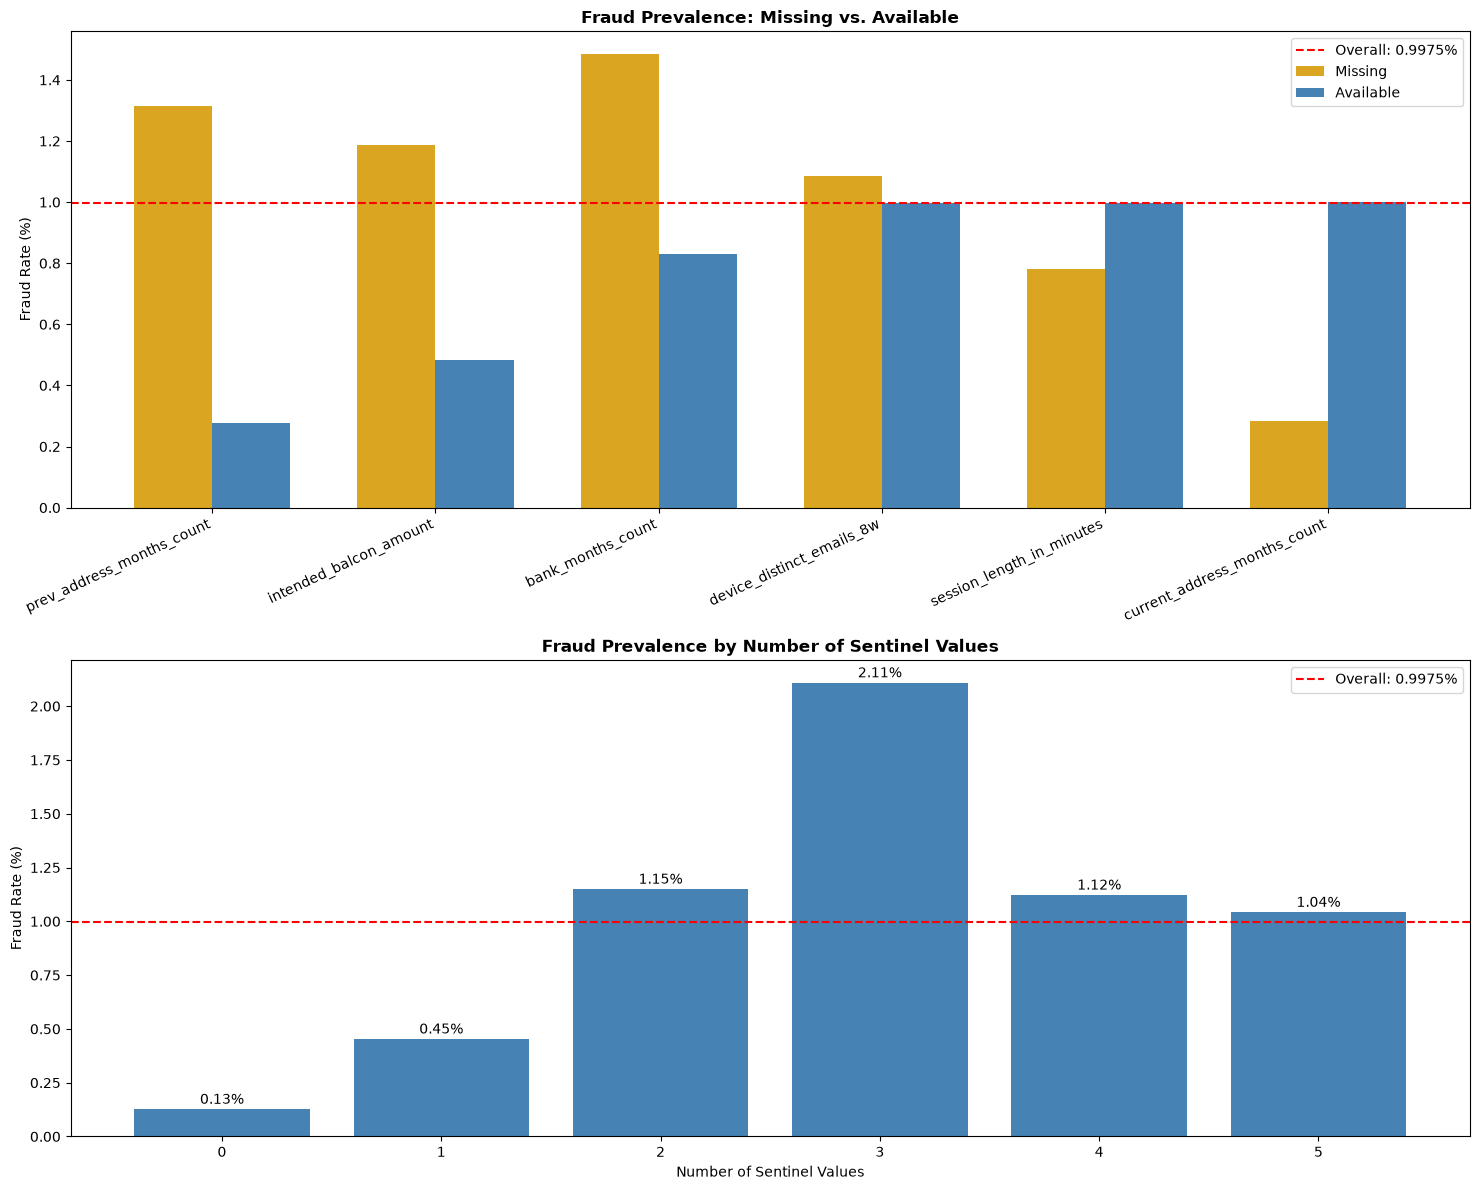

In [51]:

# =====================================================
# 9.7 Sentinel Values and Fraud Prevalence
# =====================================================

# Select the training target variable
target = train_df["fraud_bool"]

# Calculate overall training fraud prevalence
overall_fraud_rate = target.mean() * 100

print(
    f"Overall training fraud rate: "
    f"{overall_fraud_rate:.4f}%"
)

# -----------------------------------------------------
# Part 1: Fraud prevalence by sentinel status
# -----------------------------------------------------

sentinel_fraud_summary = []

for feature in sentinel_rules:

    # Identify missing and available observations
    missing_mask = sentinel_mask_df[feature]
    available_mask = ~missing_mask

    # Count applications in each group
    missing_count = int(missing_mask.sum())
    available_count = int(available_mask.sum())

    # Count fraudulent applications
    missing_fraud_count = int(
        target[missing_mask].sum()
    )

    available_fraud_count = int(
        target[available_mask].sum()
    )

    # Calculate fraud rates
    missing_fraud_rate = (
        target[missing_mask].mean() * 100
    )

    available_fraud_rate = (
        target[available_mask].mean() * 100
    )

    # Calculate fraud rate difference
    fraud_rate_difference = (
        missing_fraud_rate - available_fraud_rate
    )

    # Calculate fraud lift relative to overall prevalence
    missing_fraud_lift = (
        missing_fraud_rate / overall_fraud_rate
    )

    available_fraud_lift = (
        available_fraud_rate / overall_fraud_rate
    )

    # Store results
    sentinel_fraud_summary.append({
        "Feature": feature,
        "Missing Applications": missing_count,
        "Missing Fraud Count": missing_fraud_count,
        "Missing Fraud Rate (%)": missing_fraud_rate,
        "Available Applications": available_count,
        "Available Fraud Count": available_fraud_count,
        "Available Fraud Rate (%)": available_fraud_rate,
        "Fraud Rate Difference (pp)": fraud_rate_difference,
        "Missing Fraud Lift": missing_fraud_lift,
        "Available Fraud Lift": available_fraud_lift
    })

# Create the feature-level summary table
sentinel_fraud_df = (
    pd.DataFrame(sentinel_fraud_summary)
    .sort_values(
        by="Fraud Rate Difference (pp)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n=== FRAUD PREVALENCE BY SENTINEL STATUS ===")

show_table(sentinel_fraud_df.round(4))

# -----------------------------------------------------
# Part 2: Fraud prevalence by number of sentinel values
# -----------------------------------------------------

sentinel_count_fraud_summary = []

for count in range(len(sentinel_rules) + 1):

    # Identify applications with this sentinel count
    mask = sentinel_count_per_row == count

    # Count applications and fraud cases
    application_count = int(mask.sum())
    fraud_count = int(target[mask].sum())

    # Calculate fraud rate and lift
    if application_count > 0:

        fraud_rate = (
            fraud_count / application_count * 100
        )

        fraud_lift = (
            fraud_rate / overall_fraud_rate
        )

    else:

        fraud_rate = np.nan
        fraud_lift = np.nan

    # Store results
    sentinel_count_fraud_summary.append({
        "Sentinel Count": count,
        "Applications": application_count,
        "Fraud Count": fraud_count,
        "Fraud Rate (%)": fraud_rate,
        "Fraud Lift": fraud_lift
    })

# Create the row-level summary table
sentinel_count_fraud_df = pd.DataFrame(
    sentinel_count_fraud_summary
)

print("\n=== FRAUD PREVALENCE BY SENTINEL COUNT ===")

show_table(sentinel_count_fraud_df.round(4))

# -----------------------------------------------------
# Part 3: Visualization
# -----------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 12)
)

# Plot 1: Missing vs. available fraud rates

positions = np.arange(len(sentinel_fraud_df))
bar_width = 0.35

axes[0].bar(
    positions - bar_width / 2,
    sentinel_fraud_df["Missing Fraud Rate (%)"],
    width=bar_width,
    color="goldenrod",
    label="Missing"
)

axes[0].bar(
    positions + bar_width / 2,
    sentinel_fraud_df["Available Fraud Rate (%)"],
    width=bar_width,
    color="steelblue",
    label="Available"
)

axes[0].axhline(
    overall_fraud_rate,
    color="red",
    linestyle="--",
    label=f"Overall: {overall_fraud_rate:.4f}%"
)

axes[0].set_xticks(positions)

axes[0].set_xticklabels(
    sentinel_fraud_df["Feature"],
    rotation=25,
    ha="right"
)

axes[0].set_title(
    "Fraud Prevalence: Missing vs. Available",
    fontweight="bold"
)

axes[0].set_ylabel("Fraud Rate (%)")
axes[0].legend()

# Plot 2: Fraud rate by sentinel count

# Exclude groups with no observations
count_plot_df = sentinel_count_fraud_df[
    sentinel_count_fraud_df["Applications"] > 0
]

bars = axes[1].bar(
    count_plot_df["Sentinel Count"],
    count_plot_df["Fraud Rate (%)"],
    color="steelblue"
)

axes[1].axhline(
    overall_fraud_rate,
    color="red",
    linestyle="--",
    label=f"Overall: {overall_fraud_rate:.4f}%"
)

# Add fraud rate labels
for bar, rate in zip(
    bars,
    count_plot_df["Fraud Rate (%)"]
):

    axes[1].annotate(
        f"{rate:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center"
    )

axes[1].set_title(
    "Fraud Prevalence by Number of Sentinel Values",
    fontweight="bold"
)

axes[1].set_xlabel("Number of Sentinel Values")
axes[1].set_ylabel("Fraud Rate (%)")

axes[1].set_xticks(
    count_plot_df["Sentinel Count"]
)

axes[1].legend()

plt.tight_layout()
plt.show()



### 9.8 Missing Values and Sentinel Values — Final Findings

#### 1. Explicit Missing Values

The training dataset contains 675,666 applications
and 32 columns.

No explicit NaN values were detected.

However, the absence of NaN values does not
necessarily indicate that the dataset is complete.

#### 2. Encoded Missing Information

Six features were identified as containing encoded
missing information using feature-specific
sentinel rules.

The analysis identified:

- 1,140,326 sentinel values.
- 628,074 applications with at least one sentinel value.
- 47,592 applications without sentinel values.
- Approximately 92.96% of applications contain
  encoded missing information.
- An average of 1.6877 sentinel values per application.

The most affected features are:

- intended_balcon_amount
- prev_address_months_count
- bank_months_count

Negative values should not automatically be treated
as missing information.

Feature-specific rules are necessary to distinguish
sentinel values from valid numerical observations.

#### 3. Fraud Prevalence by Sentinel Status

The overall training fraud rate is 0.9975%.

The analysis revealed meaningful differences in
fraud prevalence between applications with missing
and available information.

| Feature | Missing Fraud Rate | Available Fraud Rate |
|---|---:|---:|
| prev_address_months_count | 1.31% | 0.28% |
| intended_balcon_amount | 1.19% | 0.48% |
| bank_months_count | 1.48% | 0.83% |
| device_distinct_emails_8w | 1.09% | 1.00% |
| session_length_in_minutes | 0.78% | 1.00% |
| current_address_months_count | 0.28% | 1.00% |

The strongest positive difference was observed in
prev_address_months_count.

Applications with missing previous address
information exhibit approximately 4.7 times the
fraud rate of applications with available information.

However, missing information is not consistently
associated with higher fraud prevalence across
all features.

#### 4. Fraud Prevalence by Sentinel Count

| Sentinel Count | Applications | Fraud Count | Fraud Rate (%) |
|---:|---:|---:|---:|
| 0 | 47,592 | 60 | 0.1261 |
| 1 | 224,029 | 1,014 | 0.4526 |
| 2 | 296,654 | 3,409 | 1.1492 |
| 3 | 106,671 | 2,249 | 2.1084 |
| 4 | 624 | 7 | 1.1218 |
| 5 | 96 | 1 | 1.0417 |
| 6 | 0 | 0 | N/A |

Fraud prevalence increases across the groups
containing zero to three sentinel values.

Applications containing three sentinel values
exhibit the highest observed fraud rate of 2.1084%.

This corresponds to approximately:

- 2.11 times the overall training fraud rate.
- 16.7 times the fraud rate of applications
  without sentinel values.

However, the relationship is not strictly monotonic.

Groups containing four or five sentinel values
have very limited sample sizes and should be
interpreted cautiously.

#### 5. Hypothesis Evaluation

**Hypothesis 1:**

The dataset may contain little or no explicit
missing information.

Supported.

No explicit NaN values were identified.

**Hypothesis 2:**

Certain numerical features may encode missing
information using sentinel values.

Supported.

Six features were identified using
feature-specific sentinel rules.

**Hypothesis 3:**

Missing information may contain useful signals
for fraud detection.

Supported at the exploratory level.

Several features exhibit different fraud rates
depending on whether information is missing
or available.

However, predictive usefulness must still be
evaluated on validation data.

**Hypothesis 4:**

Not all negative numerical values represent
missing information.

Supported.

A universal negative-value replacement rule
would be inappropriate.

#### 6. Preprocessing and Feature Engineering Implications

Based on the exploratory findings, the following
strategies should be considered:

- Preserve training observations rather than
  applying complete-case deletion.
- Apply feature-specific sentinel handling.
- Investigate binary missingness indicators.
- Investigate the number of sentinel values
  as an additional numerical feature.
- Evaluate appropriate imputation strategies.
- Fit any learned preprocessing parameters
  using training data only.
- Compare preprocessing strategies using
  temporal validation data.

Removing all applications containing sentinel
values would discard approximately 92.96%
of the training dataset.

Therefore, complete-case deletion is not
recommended as a default preprocessing strategy.

#### 7. Limitations

- The analysis identifies statistical associations,
  not causal relationships.
- Some missing-value groups contain very few
  observations.
- Missingness patterns may be correlated
  with other features.
- Predictive usefulness has not yet been
  established through model evaluation.
- Missingness patterns may change over time.

All exploratory findings in this section were
obtained using training months 0–4 only.

#### 8. Conclusion

Encoded missing information is a widespread
characteristic of the training dataset.

Missingness appears to contain potentially
valuable information for fraud detection.

Therefore, missing information should not be
treated exclusively as a data-quality problem.

Its potential predictive contribution should
be investigated during preprocessing and
model development.

No original dataset values were modified,
no applications were removed, and no new
model input features were created during
this exploratory analysis.
